# **Project Name**    - Bank Term Deposit Prediction with Spark ML


##### **Project Type**    - Classification
##### **Contribution**    - Individual
##### **Team Member 1 -** Taha Saifee


# **Project Summary -**

This notebook is the predictive modeling part of my distributed ML project on the bank marketing dataset. The bank called its clients to sell a term deposit, and the question is simple: can we predict, before calling, which clients will say yes? I did everything with Apache Spark and Spark ML, so the same code would also run on a cluster with much more data than the 4,521 clients in bank.csv.

I started by loading the csv into a Spark DataFrame and checking it. There are 17 columns, no nulls and no duplicate rows. The missing information hides in placeholder values: 'unknown' in job, education, contact and poutcome, and pdays = -1 for clients who were never contacted before. I found that pdays = -1, previous = 0 and poutcome = 'unknown' describe exactly the same 3,705 clients. Only 11.5% of the clients subscribed, so the target is imbalanced.

The charts and three hypothesis tests gave a clear picture. Clients who subscribed had much longer calls (median 442 seconds against 167). A success in the previous campaign is the strongest signal I found: 64.3% of those clients subscribed again, against 9.1% of clients never contacted before. May had the most calls but the worst success rate (6.7%), while the quiet months converted over 40%. Clients reached on an unknown contact type, clients with a housing loan and clients called many times all subscribed less often. Clients over 60 and students subscribed the most.

For the features, I kept 'unknown' as its own category, split pdays into a 0/1 flag and a cleaned value, capped balance, duration, campaign and previous at the 1st and 99th percentiles of the training set, and used log1p on the skewed counts. Categorical columns go through StringIndexer and OneHotEncoder, then everything is put into one vector with VectorAssembler. All of this sits inside a single Spark ML Pipeline, together with the model, so new data later gets exactly the same treatment. A chi-square test showed that default has no link with the target (p = 0.93), so I dropped it, and I also dropped day.

One column needs special care: duration is only known after the call has ended. The authors of the dataset say it should be left out of a realistic model. I trained every model with and without it. With duration the models reach an AUC-ROC of about 0.89, without it about 0.74. That number can't be used to decide who to call, so my final model leaves duration out.

I trained three models with class weights to handle the imbalance: logistic regression, random forest and gradient boosted trees. Each one was tuned with ParamGridBuilder and a 3 fold CrossValidator, scored on the area under the precision-recall curve. The tuned logistic regression had the best cross validation score (0.354) and on the test set it reaches an AUC-ROC of 0.744 and an AUC-PR of 0.337, about three times the 0.108 a random guess would get. In practice, if the bank only called the 31% of clients the model flags, it would still reach 60% of the people who subscribe, and twice as many calls would end in a sale.

Spark trains in parallel. The training data is split into 8 partitions, each iteration of logistic regression computes gradients on every partition and combines them with treeAggregate, the tree models collect split statistics per partition, and CrossValidator trains 4 parameter combinations at the same time. The final PipelineModel is saved to disk and reloaded, and the same model can be used inside the Spark Streaming part of the project.

# **GitHub Link -**

https://github.com/Tahascommit/bank-distributed-ml

# **Problem Statement**


**A Portuguese bank ran direct marketing campaigns by phone to sell term deposits to its clients. Most calls do not lead to a sale: only 11.5% of the clients in the data subscribed. Every call costs the bank agent time and can annoy clients who are not interested.**

**The goal is to build a classification model with Spark ML that predicts, before the call, whether a client will subscribe to a term deposit (the column y). With a good model the bank can call the clients with the highest chance first, waste fewer calls, and plan its campaigns better. The model has to be built in a distributed way, so it can work on much larger data than this sample.**

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required. 
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits. 
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule. 

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os, sys, glob, shutil, subprocess, warnings, urllib.request
warnings.filterwarnings("ignore")

# Spark needs Java. On my Mac it is the Homebrew Java 17, on Colab it gets installed if it is missing
MAC_JAVA = "/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home"
if os.path.isdir(MAC_JAVA):
    os.environ["JAVA_HOME"] = MAC_JAVA
elif shutil.which("java") is None:
    subprocess.run("apt-get update -qq && apt-get install -y -qq openjdk-17-jdk-headless > /dev/null",
                   shell=True, check=True)
    os.environ["JAVA_HOME"] = glob.glob("/usr/lib/jvm/java-17-openjdk-*")[0]

# Spark starts separate Python worker processes, they must use this same Python (not the system one)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# only show errors from Spark's own (Java) logging, otherwise the startup warnings end up in the notebook
# (written to the temp folder: a space in the path would break the Java option)
import tempfile
LOG4J = os.path.join(tempfile.gettempdir(), "log4j2-errors-only.properties")
with open(LOG4J, "w") as f:
    f.write("rootLogger.level = error\nrootLogger.appenderRef.console.ref = console\n"
            "appender.console.type = Console\nappender.console.name = console\nappender.console.target = SYSTEM_ERR\n"
            "appender.console.layout.type = PatternLayout\nappender.console.layout.pattern = %d{HH:mm:ss} %p %c{1}: %m%n\n"
            "logger.pyspark.name = org.apache.spark.api.python.PythonGatewayServer\nlogger.pyspark.level = error\n")

# pyspark 3.5 works with Java 8, 11 and 17, so the same notebook runs locally and on Colab
try:
    import pyspark
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark==3.5.9"], check=True)
    import pyspark

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import (StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler,
                                SQLTransformer, PCA)
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.stat import ChiSquareTest, Correlation, Summarizer
from pyspark.ml.functions import vector_to_array

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
NO_COLOR, YES_COLOR = "#2a78d6", "#eb6834"   # the same color for "no" and "yes" in every chart
print("pyspark", pyspark.__version__)

pyspark 3.5.9


### Dataset Loading

In [2]:
# Load Dataset
# start Spark in local mode with all the CPU cores of this machine
spark = (SparkSession.builder
         .master("local[*]")
         .appName("bank-term-deposit-spark-ml")
         .config("spark.driver.memory", "2g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.driver.extraJavaOptions", f"-Dlog4j2.configurationFile=file:{LOG4J}")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

LOCAL_DATA = "../data/bank.csv"
DATA_URL = "https://raw.githubusercontent.com/Tahascommit/bank-distributed-ml/main/data/bank.csv"
if os.path.exists(LOCAL_DATA):
    data_path = LOCAL_DATA
else:  # on Colab: download the file from the GitHub repo first
    data_path = "bank.csv"
    urllib.request.urlretrieve(DATA_URL, data_path)

# inferSchema makes Spark read the numbers as integers instead of strings
df = spark.read.csv(data_path, header=True, inferSchema=True).cache()
print(f"Spark {spark.version} running on {spark.sparkContext.defaultParallelism} cores, data loaded from {data_path}")

Spark 3.5.9 running on 12 cores, data loaded from ../data/bank.csv


### Dataset First View

In [3]:
# Dataset First Look
df.limit(5).toPandas()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print(f"rows: {df.count()}, columns: {len(df.columns)}")

rows: 4521, columns: 17


### Dataset Information

In [5]:
# Dataset Info
df.printSchema()
print("partitions of the DataFrame:", df.rdd.getNumPartitions())

root
 |-- age: integer (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- default: string (nullable = true)
 |-- balance: integer (nullable = true)
 |-- housing: string (nullable = true)
 |-- loan: string (nullable = true)
 |-- contact: string (nullable = true)
 |-- day: integer (nullable = true)
 |-- month: string (nullable = true)
 |-- duration: integer (nullable = true)
 |-- campaign: integer (nullable = true)
 |-- pdays: integer (nullable = true)
 |-- previous: integer (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- y: string (nullable = true)

partitions of the DataFrame: 1


#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print("duplicate rows:", df.count() - df.dropDuplicates().count())

duplicate rows: 0


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
# real nulls per column, and the placeholder values this dataset uses instead of nulls
nulls = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).toPandas().T
nulls.columns = ["nulls"]
cat_cols = [c for c, t in df.dtypes if t == "string" and c != "y"]
placeholders = df.select([F.sum((F.col(c) == "unknown").cast("int")).alias(c) for c in cat_cols]).toPandas().T
placeholders.columns = ["placeholder values"]
missing = nulls.join(placeholders, how="left").fillna(0).astype(int)
missing.loc["pdays", "placeholder values"] = df.filter(F.col("pdays") == -1).count()  # -1 = never contacted before
missing

,nulls,placeholder values
age,0,0
job,0,38
marital,0,0
education,0,187
default,0,0
balance,0,0
housing,0,0
loan,0,0
contact,0,1324
day,0,0


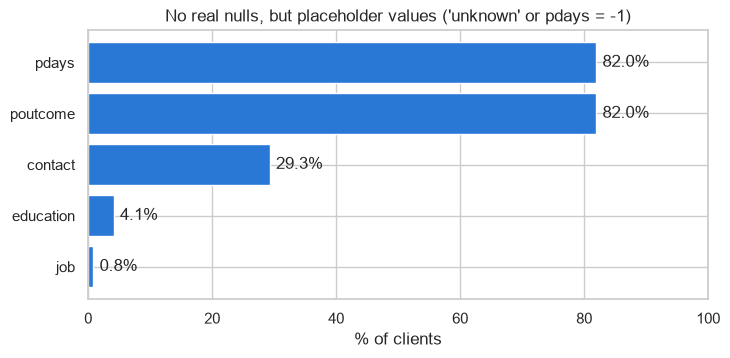

In [8]:
# Visualizing the missing values
share = (100 * missing["placeholder values"] / df.count()).sort_values()
share = share[share > 0]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(share.index, share.values, color=NO_COLOR)
for i, v in enumerate(share.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set_xlabel("% of clients")
ax.set_title("No real nulls, but placeholder values ('unknown' or pdays = -1)")
ax.set_xlim(0, 100)
plt.show()

### What did you know about your dataset?

The dataset has 4,521 clients and 17 columns: 7 numeric (age, balance, day, duration, campaign, pdays, previous) and 10 text columns, including the target y. Spark read it into a single partition because the file is small (about 375 KB).

There are no nulls and no duplicate rows, so on the surface the data is clean. But some values work like missing values:
- contact is 'unknown' for 1,324 clients and education for 187, job for 38.
- poutcome is 'unknown' for 3,705 clients, and these are exactly the clients with pdays = -1 and previous = 0, so it simply means they were never contacted before.

The target is imbalanced: 521 clients said yes (11.5%) and 4,000 said no. That will matter a lot for the modeling, because a model that always says "no" would already be 88.5% accurate.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
df.columns

['age',
 'job',
 'marital',
 'education',
 'default',
 'balance',
 'housing',
 'loan',
 'contact',
 'day',
 'month',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'y']

In [10]:
# Dataset Describe
df.summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max").toPandas().set_index("summary").T

summary,count,mean,stddev,min,25%,50%,75%,max
age,4521,41.17009511170095,10.576210958711263,19,33,39,49,87
job,4521,None,None,admin.,None,None,None,unknown
marital,4521,None,None,divorced,None,None,None,single
education,4521,None,None,primary,None,None,None,unknown
default,4521,None,None,no,None,None,None,yes
balance,4521,1422.6578190665782,3009.6381424673395,-3313,69,444,1480,71188
housing,4521,None,None,no,None,None,None,yes
loan,4521,None,None,no,None,None,None,yes
contact,4521,None,None,cellular,None,None,None,unknown
day,4521,15.915284229152842,8.247667327229934,1,9,16,21,31


### Variables Description 

- **age**: age of the client (19 to 87)
- **job**: type of job, 12 categories including 'unknown'
- **marital**: married, single or divorced
- **education**: primary, secondary, tertiary or unknown
- **default**: does the client have credit in default (yes/no)
- **balance**: average yearly balance in euros, from -3,313 to 71,188
- **housing**: has a housing loan (yes/no)
- **loan**: has a personal loan (yes/no)
- **contact**: how the client was contacted (cellular, telephone, unknown)
- **day**: day of the month of the last contact
- **month**: month of the last contact
- **duration**: length of the last call in seconds. Only known after the call, so it can't be used to decide who to call
- **campaign**: number of calls to this client during this campaign, including the last one
- **pdays**: days since the client was last contacted in an earlier campaign, -1 means never contacted
- **previous**: number of contacts before this campaign
- **poutcome**: outcome of the previous campaign (success, failure, other, unknown)
- **y**: the target, did the client subscribe to a term deposit (yes/no)

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
df.agg(*[F.countDistinct(c).alias(c) for c in df.columns]).toPandas().T.rename(columns={0: "unique values"})

,unique values
age,67
job,12
marital,3
education,4
default,2
balance,2353
housing,2
loan,2
contact,3
day,31


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Write your code to make your dataset analysis ready.
# analysis version of the data: numeric target, age groups, month number and quarter,
# and a flag for clients contacted in an earlier campaign (pdays = -1 means never contacted)
MONTHS = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_no = F.create_map(*[x for i, m in enumerate(MONTHS, 1) for x in (F.lit(m), F.lit(i))])

bank = (df
        .withColumn("label", F.when(F.col("y") == "yes", 1.0).otherwise(0.0))
        .withColumn("age_group", F.when(F.col("age") < 30, "under 30")
                                  .when(F.col("age") < 40, "30-39")
                                  .when(F.col("age") < 50, "40-49")
                                  .when(F.col("age") < 60, "50-59")
                                  .otherwise("60+"))
        .withColumn("month_no", month_no[F.col("month")])
        .withColumn("quarter", F.concat(F.lit("Q"), F.ceil(F.col("month_no") / 3).cast("int")))
        .withColumn("prev_contacted", (F.col("pdays") != -1).cast("int"))
        .cache())


def rate_by(data, col):
    """clients, subscribers and subscription rate (%) per value of a column, computed by Spark"""
    return (data.groupBy(col)
                .agg(F.count("*").alias("clients"), F.sum("label").cast("int").alias("subscribed"))
                .withColumn("rate_pct", F.round(100 * F.col("subscribed") / F.col("clients"), 1))
                .orderBy(F.desc("rate_pct"))
                .toPandas())


overall = bank.agg(F.avg("label")).first()[0]
print(f"overall subscription rate: {100 * overall:.1f}%")
print("pdays = -1, previous = 0 and poutcome = 'unknown' are the same clients:",
      bank.filter("pdays = -1").count(), bank.filter("previous = 0").count(),
      bank.filter("poutcome = 'unknown'").count(),
      bank.filter("pdays = -1 AND previous = 0 AND poutcome = 'unknown'").count())
bank.select("age", "age_group", "month", "month_no", "quarter", "pdays", "prev_contacted", "y", "label").show(5)

overall subscription rate: 11.5%
pdays = -1, previous = 0 and poutcome = 'unknown' are the same clients: 3705 3705 3705 3705
+---+---------+-----+--------+-------+-----+--------------+---+-----+
|age|age_group|month|month_no|quarter|pdays|prev_contacted|  y|label|
+---+---------+-----+--------+-------+-----+--------------+---+-----+
| 30|    30-39|  oct|      10|     Q4|   -1|             0| no|  0.0|
| 33|    30-39|  may|       5|     Q2|  339|             1| no|  0.0|
| 35|    30-39|  apr|       4|     Q2|  330|             1| no|  0.0|
| 30|    30-39|  jun|       6|     Q2|   -1|             0| no|  0.0|
| 59|    50-59|  may|       5|     Q2|   -1|             0| no|  0.0|
+---+---------+-----+--------+-------+-----+--------------+---+-----+
only showing top 5 rows



### What all manipulations have you done and insights you found?

I made an analysis version of the data called bank, with:
- **label**: 1.0 for yes and 0.0 for no, because Spark ML needs a numeric target
- **age_group**: under 30, 30-39, 40-49, 50-59 and 60+, to compare groups in the charts
- **month_no** and **quarter**: the month as a number (with a map, so the months sort in calendar order) and the quarter of the year
- **prev_contacted**: 1 if the client was contacted in an earlier campaign

I also wrote a small helper, rate_by, that computes the number of clients, subscribers and the subscription rate per category in Spark and only returns the small result table.

What I found: the overall subscription rate is 11.5%. And the check confirmed that pdays = -1, previous = 0 and poutcome = 'unknown' are the same 3,705 clients, so these three columns describe one fact: the client was never contacted before.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Target variable: did the client subscribe? (Univariate)

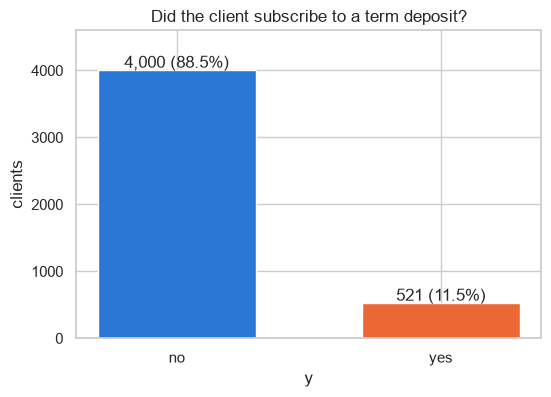

In [13]:
# Chart - 1 visualization code
target = bank.groupBy("y").count().orderBy("y").toPandas()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(target["y"], target["count"], color=[NO_COLOR, YES_COLOR], width=0.6)
for b, c in zip(bars, target["count"]):
    ax.text(b.get_x() + b.get_width() / 2, c + 40, f"{c:,} ({100 * c / target['count'].sum():.1f}%)", ha="center")
ax.set_title("Did the client subscribe to a term deposit?")
ax.set_xlabel("y")
ax.set_ylabel("clients")
ax.set_ylim(0, 4600)
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart with counts and percentages is the clearest way to show how a yes/no target is split, and it is the first thing to check for a classification problem.

##### 2. What is/are the insight(s) found from the chart?

Only 521 of the 4,521 clients subscribed (11.5%), 4,000 did not (88.5%). The classes are very imbalanced.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

It helps in two ways. For the business, it shows that almost 9 out of 10 calls are wasted, so there is a lot to gain from calling the right people first. For the model, it tells me that accuracy is a misleading metric here (always saying no gives 88.5%) and that I need class weights and metrics like recall and AUC-PR. The low rate itself is a negative sign for the campaign: the bank spends most of its calling time on clients who say no.

#### Chart - 2 - Age distribution (Univariate)

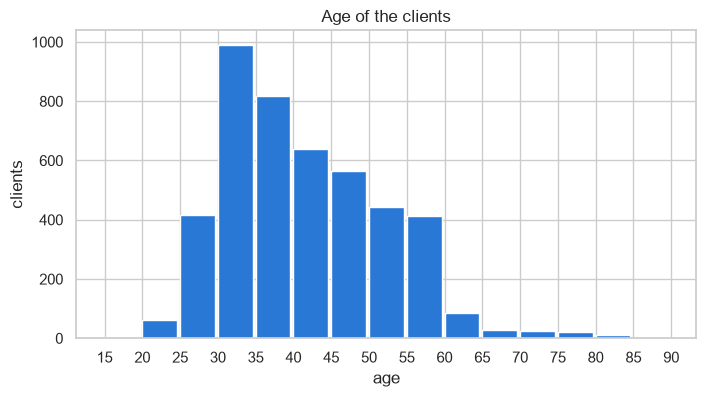

median age: 39.0


In [14]:
# Chart - 2 visualization code
# the histogram is computed by Spark (rdd.histogram), only the bin counts come back to Python
bins = list(range(15, 95, 5))
edges, counts = bank.select("age").rdd.map(lambda r: float(r[0])).histogram([float(b) for b in bins])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(edges[:-1], counts, width=4.6, align="edge", color=NO_COLOR)
ax.set_xticks(bins)
ax.set_xlabel("age")
ax.set_ylabel("clients")
ax.set_title("Age of the clients")
plt.show()
print("median age:", bank.approxQuantile("age", [0.5], 0.0)[0])

##### 1. Why did you pick the specific chart?

A histogram shows the shape of a numeric column. I let Spark compute the bin counts with rdd.histogram, so only 15 numbers come back to Python instead of every row.

##### 2. What is/are the insight(s) found from the chart?

Most clients are between 30 and 50 years old and the median age is 39. There are few clients under 25 and very few over 60, the tail on the right is long (the oldest client is 87).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

The bank's client base is mostly working age adults. Because older clients are few, their high subscription rate (chart 10) is easy to miss in the overall numbers. There is no negative insight here, but the small number of young clients means students and young workers are a small market.

#### Chart - 3 - Account balance distribution (Univariate)

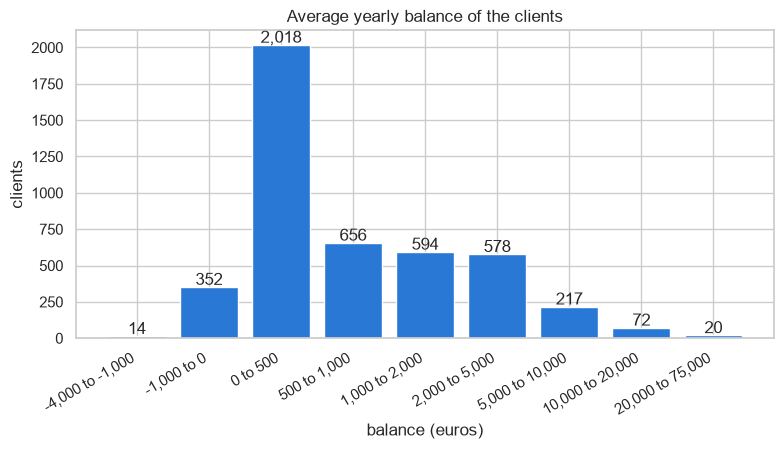

1% / 25% / 50% / 75% / 99% quantiles: [-673.0, 69.0, 444.0, 1480.0, 14220.0]
clients with a negative balance: 366


In [15]:
# Chart - 3 visualization code
# balance has a long tail and negative values, so I use uneven bins that still show the shape
bins = [-4000, -1000, 0, 500, 1000, 2000, 5000, 10000, 20000, 75000]
edges, counts = bank.select("balance").rdd.map(lambda r: float(r[0])).histogram([float(b) for b in bins])
labels = [f"{int(edges[i]):,} to {int(edges[i + 1]):,}" for i in range(len(edges) - 1)]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(labels, counts, color=NO_COLOR)
for i, c in enumerate(counts):
    ax.text(i, c + 15, f"{c:,}", ha="center")
ax.set_xlabel("balance (euros)")
ax.set_ylabel("clients")
ax.set_title("Average yearly balance of the clients")
plt.xticks(rotation=30, ha="right")
plt.show()
q = bank.approxQuantile("balance", [0.01, 0.25, 0.5, 0.75, 0.99], 0.0)
print("1% / 25% / 50% / 75% / 99% quantiles:", q)
print("clients with a negative balance:", bank.filter("balance < 0").count())

##### 1. Why did you pick the specific chart?

Balance has negative values and a very long tail, so a normal histogram would be one big bar. I used uneven bins so the shape is still visible, again computed by Spark.

##### 2. What is/are the insight(s) found from the chart?

Most clients have a small balance: 2,018 are between 0 and 500 euros and the median is 444. 366 clients have a negative balance. A small group is very rich: 92 clients have more than 10,000 and the maximum is 71,188. The 99th percentile is 14,220.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

It tells the bank that the clients with a lot of money are rare, and they are the ones who can actually put money in a deposit. The 366 clients in the negative are a negative signal: selling them a deposit makes little sense. For modeling, the long tail means I should cap the extreme balances so they don't dominate a linear model.

#### Chart - 4 - Number of contacts in this campaign (Univariate)

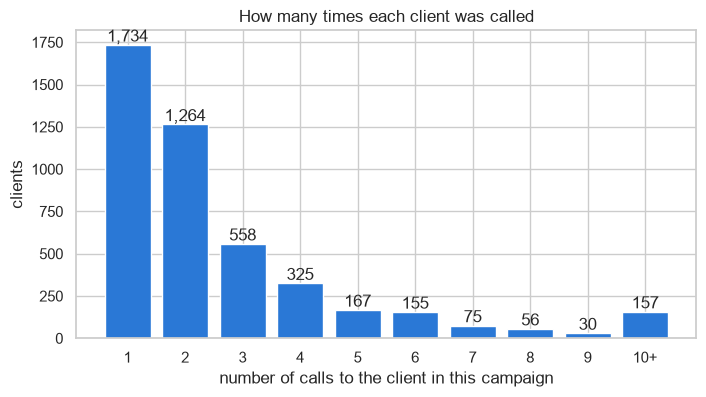

In [16]:
# Chart - 4 visualization code
contacts = (bank.withColumn("contacts", F.when(F.col("campaign") >= 10, "10+").otherwise(F.col("campaign").cast("string")))
                .groupBy("contacts").count().toPandas().set_index("contacts"))
order = [str(i) for i in range(1, 10)] + ["10+"]
contacts = contacts.reindex(order)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(contacts.index, contacts["count"], color=NO_COLOR)
for i, c in enumerate(contacts["count"]):
    ax.text(i, c + 20, f"{c:,}", ha="center")
ax.set_xlabel("number of calls to the client in this campaign")
ax.set_ylabel("clients")
ax.set_title("How many times each client was called")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of counts per number of calls shows how hard the bank pushed each client during the campaign.

##### 2. What is/are the insight(s) found from the chart?

1,734 clients were called once and 1,264 twice, but 157 clients were called 10 times or more, and the maximum is 50 calls.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Calling the same client 10 or more times costs a lot and, as chart 11 shows, almost never works. That is a clear negative growth point: these repeated calls cost money and may annoy clients. A cap on the number of calls per client would save time.

#### Chart - 5 - Call duration for subscribers and non subscribers (Bivariate, numerical - categorical)

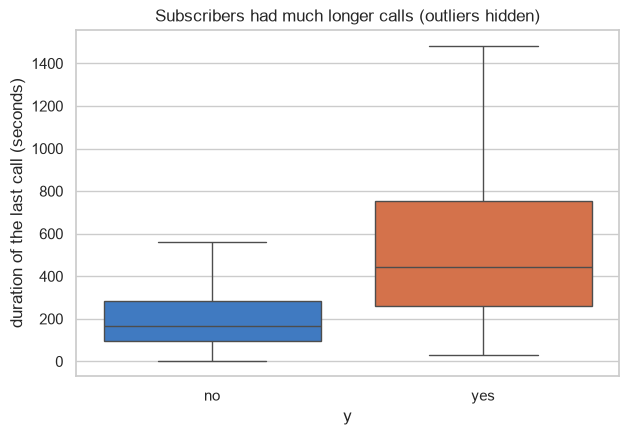

no median duration: 167.0 seconds
yes median duration: 442.0 seconds


In [17]:
# Chart - 5 visualization code
dur = bank.select("duration", "y").toPandas()
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=dur, x="y", y="duration", order=["no", "yes"], palette=[NO_COLOR, YES_COLOR], showfliers=False, ax=ax)
ax.set_ylabel("duration of the last call (seconds)")
ax.set_title("Subscribers had much longer calls (outliers hidden)")
plt.show()
for v in ["no", "yes"]:
    print(v, "median duration:", bank.filter(F.col("y") == v).approxQuantile("duration", [0.5], 0.0)[0], "seconds")

##### 1. Why did you pick the specific chart?

A box plot is the standard way to compare a numeric column between two groups. I hid the extreme outliers so the boxes are readable.

##### 2. What is/are the insight(s) found from the chart?

Clients who subscribed had much longer calls: the median is 442 seconds against 167 seconds for clients who said no. The whole box for 'yes' is higher.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Long calls go together with sales, so agents should get time to properly explain the product. But duration is only known after the call ends, so it cannot be used to choose who to call. If a model uses it, the results look much better than they really are. That is why I train every model with and without duration later.

#### Chart - 6 - Subscription rate by job (Bivariate, categorical - categorical)

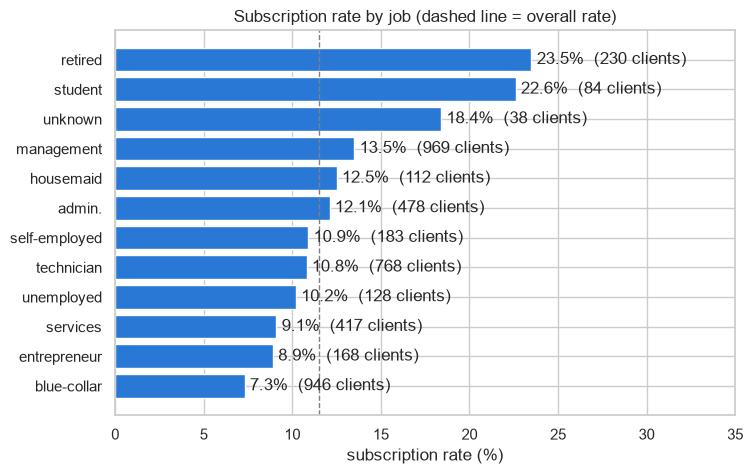

In [18]:
# Chart - 6 visualization code
jobs = rate_by(bank, "job").sort_values("rate_pct")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(jobs["job"], jobs["rate_pct"], color=NO_COLOR)
for i, (r, n) in enumerate(zip(jobs["rate_pct"], jobs["clients"])):
    ax.text(r + 0.3, i, f"{r}%  ({n} clients)", va="center")
ax.axvline(100 * overall, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("subscription rate (%)")
ax.set_title("Subscription rate by job (dashed line = overall rate)")
ax.set_xlim(0, 35)
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart sorted by rate makes it easy to compare 12 job categories, and the client counts next to the bars show which groups are big.

##### 2. What is/are the insight(s) found from the chart?

Retired clients (23.5%) and students (22.6%) subscribe the most, far above the overall 11.5%. Blue-collar workers have the lowest rate (7.3%) even though they are the second biggest group (946 clients). Entrepreneurs and services are also below average.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

The bank can focus more on retired clients and students, who say yes about twice as often as average. The low rate of blue-collar workers is a negative point: a lot of calls go to a large group that rarely buys, so a different product or message may work better for them.

#### Chart - 7 - Contacts and success rate by month (Bivariate, time - categorical)

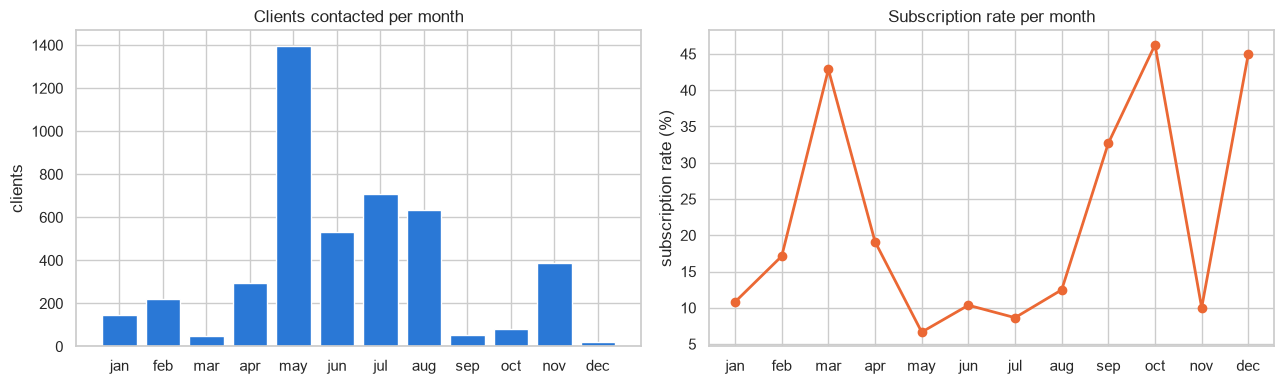

,month,month_no,contacts,rate_pct
0,jan,1,148,10.8
1,feb,2,222,17.1
2,mar,3,49,42.9
3,apr,4,293,19.1
4,may,5,1398,6.7
5,jun,6,531,10.4
6,jul,7,706,8.6
7,aug,8,633,12.5
8,sep,9,52,32.7
9,oct,10,80,46.2


In [19]:
# Chart - 7 visualization code
months = (bank.groupBy("month", "month_no")
              .agg(F.count("*").alias("contacts"), F.avg("label").alias("rate"))
              .orderBy("month_no").toPandas())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(months["month"], months["contacts"], color=NO_COLOR)
axes[0].set_title("Clients contacted per month")
axes[0].set_ylabel("clients")
axes[1].plot(months["month"], 100 * months["rate"], marker="o", color=YES_COLOR, linewidth=2)
axes[1].set_title("Subscription rate per month")
axes[1].set_ylabel("subscription rate (%)")
plt.tight_layout()
plt.show()
months.assign(rate_pct=(100 * months["rate"]).round(1)).drop(columns="rate")

##### 1. Why did you pick the specific chart?

Two charts side by side, one for the number of contacts and one for the success rate, show both sides of the monthly pattern without mixing two scales on one axis.

##### 2. What is/are the insight(s) found from the chart?

May has by far the most contacts (1,398) but the lowest success rate (6.7%). June to August are also busy with rates between 8.6% and 12.5%. The months with few calls do much better: March 42.9%, September 32.7%, October 46.2% and December 45.0%.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

This is one of the most useful findings for planning. The bank calls the most in the months where it works the worst. Moving part of the effort from May to other months could raise the number of deposits. The May campaign itself is a negative result: a big effort with very low return.

#### Chart - 8 - Subscription rate by outcome of the previous campaign (Bivariate, categorical - categorical)

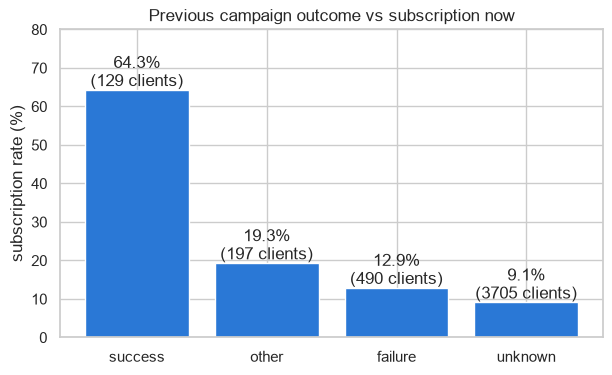

In [20]:
# Chart - 8 visualization code
pout = rate_by(bank, "poutcome")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(pout["poutcome"], pout["rate_pct"], color=NO_COLOR)
for i, (r, n) in enumerate(zip(pout["rate_pct"], pout["clients"])):
    ax.text(i, r + 1, f"{r}%\n({n} clients)", ha="center")
ax.set_ylabel("subscription rate (%)")
ax.set_title("Previous campaign outcome vs subscription now")
ax.set_ylim(0, 80)
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of the subscription rate per category is the clearest way to compare the 4 outcomes of the previous campaign.

##### 2. What is/are the insight(s) found from the chart?

64.3% of the clients whose last campaign was a success subscribed again (83 of 129). After a failure it is 12.9%, for 'other' 19.3%, and clients never contacted before (unknown) have the lowest rate, 9.1%.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Very positive: clients who bought before are by far the best people to call, and the bank should always start with them. The negative side is that this group is tiny (129 clients) and most clients (3,705) were never contacted before, where the success rate is low.

#### Chart - 9 - Subscription rate by contact type (Bivariate, categorical - categorical)

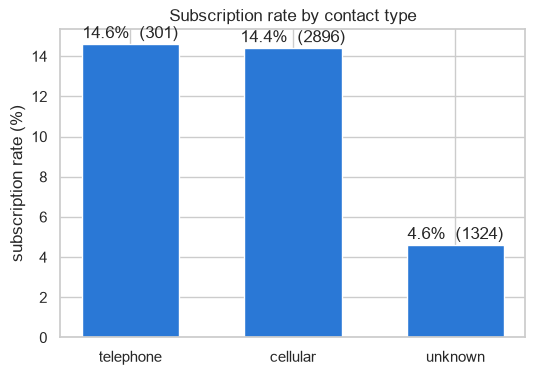

In [21]:
# Chart - 9 visualization code
contact = rate_by(bank, "contact")
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(contact["contact"], contact["rate_pct"], color=NO_COLOR, width=0.6)
for i, (r, n) in enumerate(zip(contact["rate_pct"], contact["clients"])):
    ax.text(i, r + 0.3, f"{r}%  ({n})", ha="center")
ax.set_ylabel("subscription rate (%)")
ax.set_title("Subscription rate by contact type")
plt.show()

##### 1. Why did you pick the specific chart?

A simple bar chart compares the 3 contact types and shows the number of clients behind each rate.

##### 2. What is/are the insight(s) found from the chart?

Cellular (14.4%) and telephone (14.6%) are about the same, but clients with an unknown contact type subscribe only 4.6% of the time, and they are a big group (1,324 clients).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

The way of calling (mobile or landline) does not matter much. The 'unknown' group is a negative point: these clients are much less likely to subscribe, and the bank does not even record how it reached them. Recording the contact type properly would help future campaigns.

#### Chart - 10 - Subscription rate by age group (Bivariate, categorical - categorical)

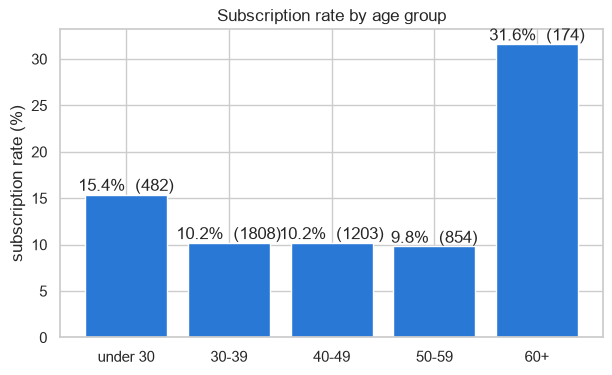

In [22]:
# Chart - 10 visualization code
ages = rate_by(bank, "age_group").set_index("age_group").reindex(["under 30", "30-39", "40-49", "50-59", "60+"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(ages.index, ages["rate_pct"], color=NO_COLOR)
for i, (r, n) in enumerate(zip(ages["rate_pct"], ages["clients"])):
    ax.text(i, r + 0.4, f"{r}%  ({n})", ha="center")
ax.set_ylabel("subscription rate (%)")
ax.set_title("Subscription rate by age group")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart per age group shows if the subscription rate changes with age, which a single correlation number would hide.

##### 2. What is/are the insight(s) found from the chart?

Clients aged 60 and over subscribe the most (31.6%), then clients under 30 (15.4%). The three middle groups are all around 10%.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Older clients, who usually have more savings (balance grows with age), are the best target and the youngest clients are second. The middle aged groups, which are most of the clients, are a harder sell. Age is not linear here, which also suggests that tree models might handle it better than a straight line.

#### Chart - 11 - Subscription rate by number of calls in this campaign (Bivariate, numerical - numerical)

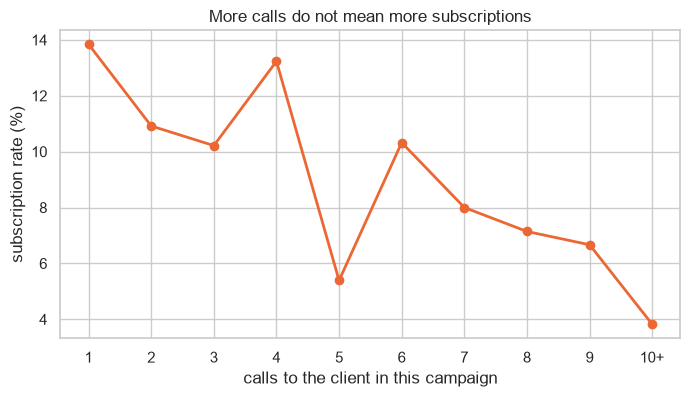

In [23]:
# Chart - 11 visualization code
calls = (bank.withColumn("calls", F.least(F.col("campaign"), F.lit(10)))
             .groupBy("calls").agg(F.count("*").alias("clients"), F.avg("label").alias("rate"))
             .orderBy("calls").toPandas())
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(calls["calls"], 100 * calls["rate"], marker="o", color=YES_COLOR, linewidth=2)
ax.set_xticks(range(1, 11))
ax.set_xticklabels([str(i) for i in range(1, 10)] + ["10+"])
ax.set_xlabel("calls to the client in this campaign")
ax.set_ylabel("subscription rate (%)")
ax.set_title("More calls do not mean more subscriptions")
plt.show()

##### 1. Why did you pick the specific chart?

A line chart fits an ordered number like the count of calls, and it shows the trend as the bank calls a client more and more.

##### 2. What is/are the insight(s) found from the chart?

The rate is highest for clients called once (13.8%) and drops as calls go up: around 10-11% for 2 or 3 calls, 5.4% at 5 calls and only 3.8% for clients called 10 times or more.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

More calls do not mean more sales. After a few calls the chance of a yes drops a lot, so the extra calls are mostly wasted. This is a clear negative growth insight about the current practice, and a cap of about 3 or 4 calls per client would save a lot of agent time.

#### Chart - 12 - Housing loan and personal loan vs subscription (Bivariate, categorical - categorical)

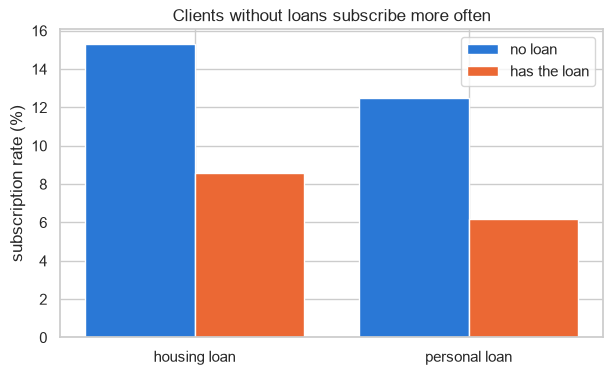

clients  subscribed  rate_pct
        housing                               
housing no          1962         301      15.3
        yes         2559         220       8.6
loan    no          3830         478      12.5
        yes          691          43       6.2

In [24]:
# Chart - 12 visualization code
house = rate_by(bank, "housing").set_index("housing").reindex(["no", "yes"])
loan = rate_by(bank, "loan").set_index("loan").reindex(["no", "yes"])
x = np.arange(2)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - 0.2, [house.loc["no", "rate_pct"], loan.loc["no", "rate_pct"]], width=0.4, color=NO_COLOR, label="no loan")
ax.bar(x + 0.2, [house.loc["yes", "rate_pct"], loan.loc["yes", "rate_pct"]], width=0.4, color=YES_COLOR, label="has the loan")
ax.set_xticks(x)
ax.set_xticklabels(["housing loan", "personal loan"])
ax.set_ylabel("subscription rate (%)")
ax.set_title("Clients without loans subscribe more often")
ax.legend()
plt.show()
pd.concat({"housing": house, "loan": loan})

##### 1. Why did you pick the specific chart?

Grouped bars put the 'no loan' and 'has the loan' rates next to each other for both loan types, so the effect of each loan is easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Clients without a housing loan subscribe 15.3% of the time against 8.6% with one. For personal loans it is 12.5% against 6.2%.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Clients without loans have money they can put away, so they are better targets for a deposit. Clients with loans are a negative signal: their money already goes to repayments, and calling them is less likely to pay off.

#### Chart - 13 - Subscription rate by education and marital status (Multivariate)

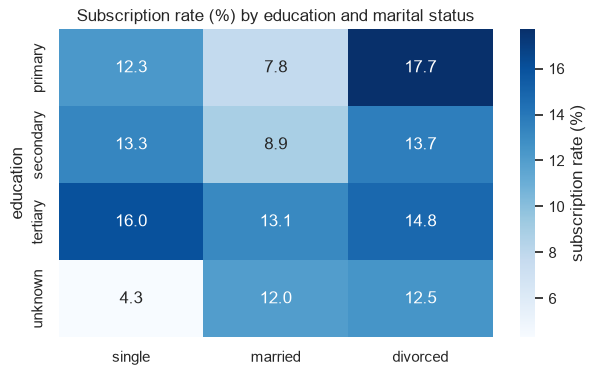

In [25]:
# Chart - 13 visualization code
# pivot in Spark: one row per education level, one column per marital status
pivot = (bank.groupBy("education").pivot("marital", ["single", "married", "divorced"])
             .agg(F.round(100 * F.avg("label"), 1)).toPandas().set_index("education")
             .reindex(["primary", "secondary", "tertiary", "unknown"]))
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "subscription rate (%)"}, ax=ax)
ax.set_title("Subscription rate (%) by education and marital status")
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap shows a rate for every combination of two categories at once, here education and marital status.

##### 2. What is/are the insight(s) found from the chart?

Single clients with tertiary education have the highest rate (16.0%), and divorced clients with primary education are also high (17.7%). Married clients with primary or secondary education are the lowest (7.8% and 8.9%). Within almost every education level, married clients subscribe less than single or divorced ones.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Married clients, who are the biggest group, are the hardest to convince, probably because their money already goes to family costs. The bank could adjust its message for them. Single clients with a university degree are a good group to target.

#### Chart - 14 - Correlation Heatmap

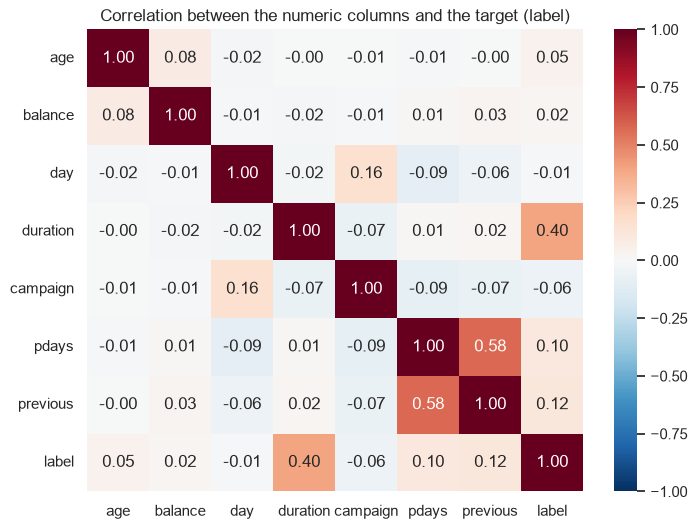

In [26]:
# Correlation Heatmap visualization code
# the correlation matrix is computed by Spark ML (pyspark.ml.stat.Correlation) on an assembled vector
num_cols = ["age", "balance", "day", "duration", "campaign", "pdays", "previous", "label"]
vec = VectorAssembler(inputCols=num_cols, outputCol="num_vec").transform(bank).select("num_vec")
corr = pd.DataFrame(Correlation.corr(vec, "num_vec", "pearson").head()[0].toArray(), index=num_cols, columns=num_cols)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between the numeric columns and the target (label)")
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap shows all the linear relationships between numeric columns in one picture. I computed the matrix with Spark ML's Correlation on an assembled vector, which works the same way on big data.

##### 2. What is/are the insight(s) found from the chart?

Duration has the strongest link with the target (0.40), then previous (0.12) and pdays (0.10). pdays and previous are correlated with each other (0.58), because both describe earlier contacts. Age and balance have a very weak correlation (0.08), and day and campaign are almost unrelated to the target. No pair of features is so strongly correlated that it would cause a real problem.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

It confirms that what happens during and before the call (call length, earlier contacts) matters much more than the client's balance or the day of the month. The strongest number, duration, is a trap for a realistic model because it is only known after the call.

#### Chart - 15 - Pair Plot

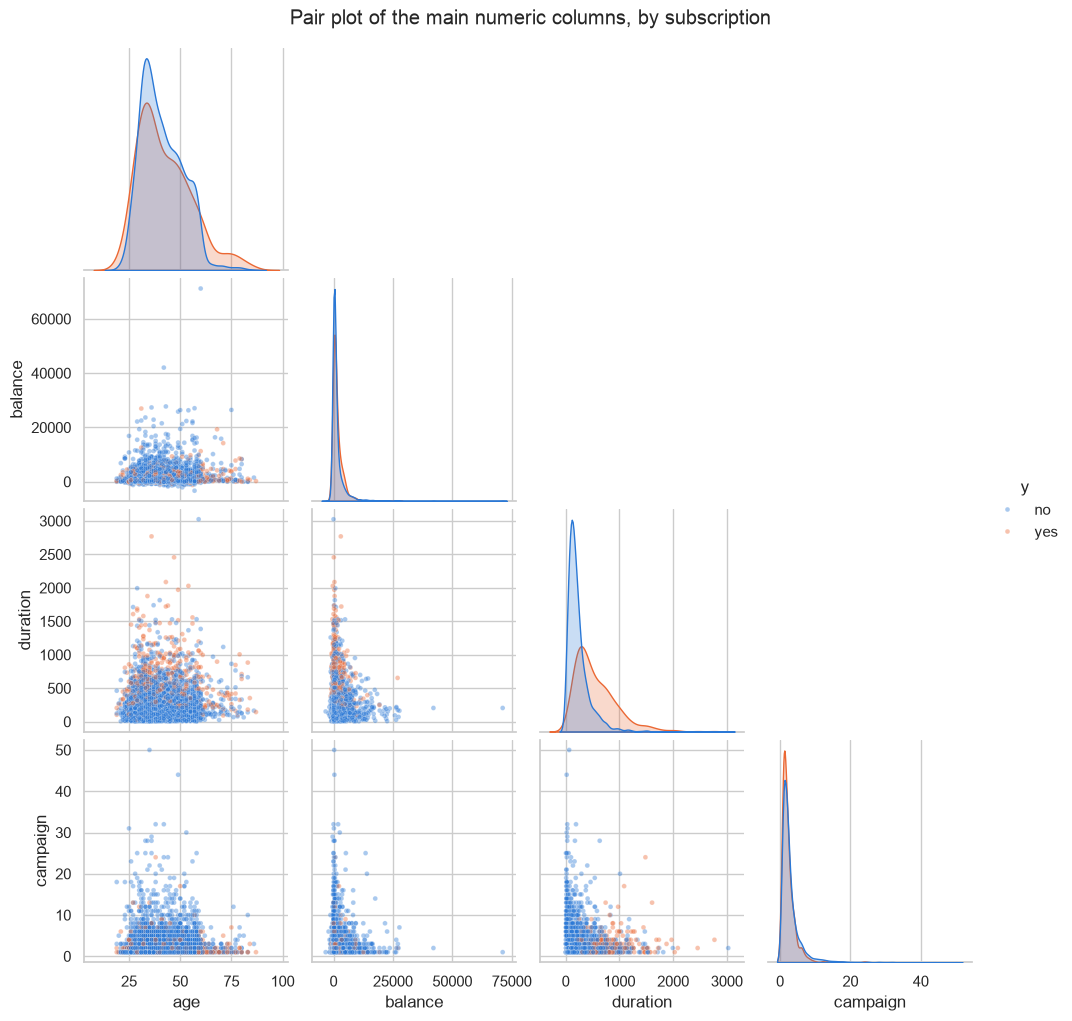

In [27]:
# Pair Plot visualization code
pair = bank.select("age", "balance", "duration", "campaign", "y").toPandas()
g = sns.pairplot(pair, hue="y", hue_order=["no", "yes"], palette=[NO_COLOR, YES_COLOR], corner=True,
                 plot_kws={"alpha": 0.4, "s": 12}, diag_kws={"common_norm": False})
g.fig.suptitle("Pair plot of the main numeric columns, by subscription", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows the distribution of each numeric column and every pairwise scatter at once, colored by the target. I used corner=True so each pair appears only once.

##### 2. What is/are the insight(s) found from the chart?

The orange points (yes) stand out mostly along duration: they are spread to much longer calls. For age, balance and campaign the yes and no points overlap almost completely, and there are no clear groups in the scatters. Balance and campaign are very skewed.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

No single numeric column separates the clients well apart from duration, so the model will have to combine many weak signals. This also tells me to transform the skewed columns before the linear model.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

From the charts I picked three statements to test:
1. Clients who subscribed had longer calls than clients who did not (chart 5).
2. Whether a client subscribes depends on the outcome of the previous campaign (chart 8).
3. Clients without a housing loan subscribe more often than clients with a housing loan (chart 12).

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- **Null hypothesis (H0):** the call duration of clients who subscribed is not higher than that of clients who did not.
- **Alternate hypothesis (H1):** clients who subscribed had longer calls.

Significance level: 0.05

#### 2. Perform an appropriate statistical test.

In [28]:
# Perform Statistical Test to obtain P-Value
# H1: clients who subscribed had longer calls than clients who did not (one sided Mann-Whitney U test)
dur_yes = np.array(bank.filter("label = 1").select("duration").rdd.flatMap(lambda r: r).collect())
dur_no = np.array(bank.filter("label = 0").select("duration").rdd.flatMap(lambda r: r).collect())
u_stat, p_value = stats.mannwhitneyu(dur_yes, dur_no, alternative="greater")
print(f"median duration: subscribed {np.median(dur_yes):.0f} s, not subscribed {np.median(dur_no):.0f} s")
print(f"U = {u_stat:,.0f}, p-value = {p_value:.3e}")
print("reject H0" if p_value < 0.05 else "fail to reject H0")

median duration: subscribed 442 s, not subscribed 167 s
U = 1,698,475, p-value = 1.165e-121
reject H0


##### Which statistical test have you done to obtain P-Value?

A one sided Mann-Whitney U test (scipy.stats.mannwhitneyu with alternative='greater'). The medians are 442 seconds for subscribers and 167 for the others, U = 1,698,475 and the p-value is 1.2e-121, so I reject H0. Subscribers really had longer calls.

##### Why did you choose the specific statistical test?

Duration is very skewed (skewness 2.77) with a long tail of very long calls, so a t-test on the means would be pulled by the outliers. Mann-Whitney compares the two groups by ranks and does not need the data to be normal. I used the one sided version because the hypothesis has a direction.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- **Null hypothesis (H0):** subscription is independent of the outcome of the previous campaign.
- **Alternate hypothesis (H1):** subscription depends on the previous outcome.

Significance level: 0.05

#### 2. Perform an appropriate statistical test.

In [29]:
# Perform Statistical Test to obtain P-Value
# H2: subscription depends on the outcome of the previous campaign (chi-square test of independence)
# Spark ML's ChiSquareTest runs the test in Spark on an indexed feature vector
pout_idx = StringIndexer(inputCol="poutcome", outputCol="poutcome_idx").fit(bank).transform(bank)
pout_vec = VectorAssembler(inputCols=["poutcome_idx"], outputCol="pout_vec").transform(pout_idx)
chi = ChiSquareTest.test(pout_vec, "pout_vec", "label").head()
print(f"chi-square = {chi.statistics[0]:.1f}, degrees of freedom = {chi.degreesOfFreedom[0]}, p-value = {chi.pValues[0]:.3e}")
print("reject H0" if chi.pValues[0] < 0.05 else "fail to reject H0")
rate_by(bank, "poutcome")

chi-square = 386.9, degrees of freedom = 3, p-value = 0.000e+00
reject H0


,poutcome,clients,subscribed,rate_pct
0,success,129,83,64.3
1,other,197,38,19.3
2,failure,490,63,12.9
3,unknown,3705,337,9.1


##### Which statistical test have you done to obtain P-Value?

A chi-square test of independence, run in Spark with pyspark.ml.stat.ChiSquareTest on the indexed poutcome column. Chi-square = 386.9 with 3 degrees of freedom, and the p-value is so small that it prints as 0. I reject H0: the previous outcome and subscription are clearly related (64.3% for 'success' against 9.1% for 'unknown').

##### Why did you choose the specific statistical test?

Both variables are categorical, and the chi-square test of independence is the standard test for that. I used Spark ML's own ChiSquareTest so the test runs in Spark, on the cluster, like everything else in this project.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- **Null hypothesis (H0):** the subscription rate of clients without a housing loan is not higher than the rate of clients with one.
- **Alternate hypothesis (H1):** clients without a housing loan subscribe more often.

Significance level: 0.05

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
# H3: clients without a housing loan subscribe more often than clients with one (one sided two-proportion z-test)
h = rate_by(bank, "housing").set_index("housing")
x1, n1 = h.loc["no", "subscribed"], h.loc["no", "clients"]
x2, n2 = h.loc["yes", "subscribed"], h.loc["yes", "clients"]
p1, p2 = x1 / n1, x2 / n2
pooled = (x1 + x2) / (n1 + n2)
z = (p1 - p2) / np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
p_value = 1 - stats.norm.cdf(z)
print(f"no housing loan: {100 * p1:.1f}% of {n1}, with housing loan: {100 * p2:.1f}% of {n2}")
print(f"z = {z:.2f}, p-value = {p_value:.3e}")
print("reject H0" if p_value < 0.05 else "fail to reject H0")

no housing loan: 15.3% of 1962, with housing loan: 8.6% of 2559
z = 7.04, p-value = 9.699e-13
reject H0


##### Which statistical test have you done to obtain P-Value?

A one sided two-proportion z-test. Clients without a housing loan subscribed 15.3% of the time (of 1,962) and clients with one 8.6% (of 2,559). z = 7.04 and the p-value is 9.7e-13, so I reject H0.

##### Why did you choose the specific statistical test?

I am comparing two proportions (subscription rates) between two independent groups, and both groups are large, so the normal approximation behind the z-test works well. It also gives a direction, which matches the one sided hypothesis.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [31]:
# Handling Missing Values & Missing Value Imputation
# there are no nulls, so nothing is imputed. Two placeholder values still need a decision:
# 1) 'unknown' in job, education, contact and poutcome stays as its own category
# 2) pdays = -1 means "never contacted before". As a number it would look like "contacted 1 day ago",
#    so it becomes a 0/1 flag (was_contacted_before in the model) plus a pdays value that is 0 when there was no earlier contact
check = bank.withColumn("pdays_clean", F.when(F.col("pdays") == -1, 0).otherwise(F.col("pdays")))
(check.groupBy("prev_contacted")
      .agg(F.count("*").alias("clients"), F.min("pdays").alias("min_pdays"), F.min("pdays_clean").alias("min_pdays_clean"),
           F.max("pdays_clean").alias("max_pdays_clean"), F.round(100 * F.avg("label"), 1).alias("subscription_rate_pct"))
      .show())
for c in ["job", "education", "contact", "poutcome"]:
    r = rate_by(bank, c).set_index(c)
    print(f"{c:10s} 'unknown': {r.loc['unknown', 'clients']:5d} clients, subscription rate {r.loc['unknown', 'rate_pct']}%")

+--------------+-------+---------+---------------+---------------+---------------------+
|prev_contacted|clients|min_pdays|min_pdays_clean|max_pdays_clean|subscription_rate_pct|
+--------------+-------+---------+---------------+---------------+---------------------+
|             1|    816|        1|              1|            871|                 22.5|
|             0|   3705|       -1|              0|              0|                  9.1|
+--------------+-------+---------+---------------+---------------+---------------------+



job        'unknown':    38 clients, subscription rate 18.4%
education  'unknown':   187 clients, subscription rate 10.2%
contact    'unknown':  1324 clients, subscription rate 4.6%


poutcome   'unknown':  3705 clients, subscription rate 9.1%


#### What all missing value imputation techniques have you used and why did you use those techniques?

There are no nulls, so I did not need to impute anything. The placeholder values needed a decision instead:
- **'unknown' stays as its own category.** It carries information: clients with an unknown contact type subscribe only 4.6% of the time, much less than the others, so replacing 'unknown' with the most common value would throw that away.
- **pdays = -1 means "never contacted before".** As a number, -1 would sit right next to "contacted 1 day ago", which is wrong. So the model gets a 0/1 flag (was_contacted_before) and a pdays value that is 0 when there was no earlier contact. The table shows the difference: clients contacted before subscribe 22.5% of the time against 9.1%.

### 2. Handling Outliers

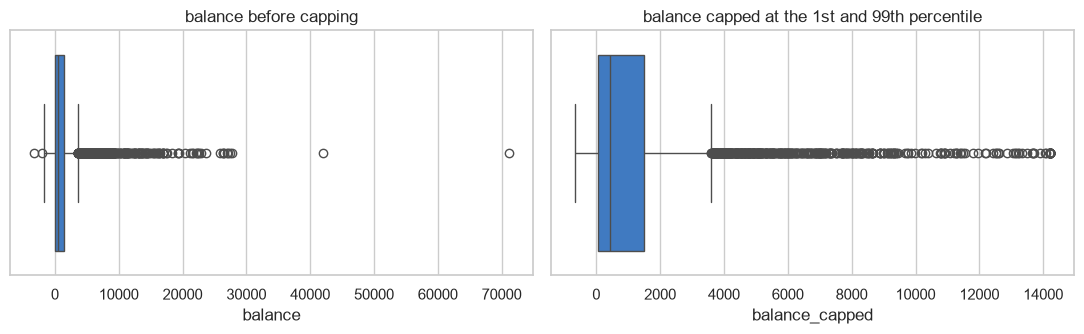

,Q1,Q3,IQR outliers,1st percentile,99th percentile,max
column,,,,,,
age,33.0,49.0,38,24.0,72.0,87
balance,69.0,1480.0,506,-673.0,14220.0,71188
duration,104.0,329.0,330,10.0,1259.0,3025
campaign,1.0,3.0,318,1.0,16.0,50
previous,0.0,0.0,816,0.0,8.0,25


In [32]:
# Handling Outliers & Outlier treatments
# count the outliers with the IQR rule, and look at the 1st and 99th percentiles used for capping
rows = []
for c in ["age", "balance", "duration", "campaign", "previous"]:
    q1, q3, p01, p99 = bank.approxQuantile(c, [0.25, 0.75, 0.01, 0.99], 0.0)
    iqr = q3 - q1
    n_out = bank.filter((F.col(c) < q1 - 1.5 * iqr) | (F.col(c) > q3 + 1.5 * iqr)).count()
    rows.append({"column": c, "Q1": q1, "Q3": q3, "IQR outliers": n_out, "1st percentile": p01,
                 "99th percentile": p99, "max": bank.agg(F.max(c)).first()[0]})
outlier_table = pd.DataFrame(rows).set_index("column")

# capping (winsorizing) at the 1st and 99th percentile, shown here on balance
p01, p99 = outlier_table.loc["balance", ["1st percentile", "99th percentile"]]
capped = bank.select("balance", F.least(F.greatest("balance", F.lit(p01)), F.lit(p99)).alias("balance_capped")).toPandas()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=capped["balance"], ax=axes[0], color=NO_COLOR)
axes[0].set_title("balance before capping")
sns.boxplot(x=capped["balance_capped"], ax=axes[1], color=NO_COLOR)
axes[1].set_title("balance capped at the 1st and 99th percentile")
plt.tight_layout()
plt.show()
outlier_table

##### What all outlier treatment techniques have you used and why did you use those techniques?

The IQR rule flags a lot of rows: 506 for balance, 330 for duration, 318 for campaign and 816 for previous (for previous every non zero value counts as an outlier, because Q1 and Q3 are both 0). These values are real, like rich clients and long calls, not data errors, so I did not delete any rows.

Instead I capped (winsorized) balance, duration, campaign and previous at the 1st and 99th percentile. Balance, for example, goes from a range of -3,313 to 71,188 down to about -679 to 14,058. The rows stay, but the extreme values can't pull the logistic regression too much. Tree models are not affected by outliers, so for them the capping changes little.

The caps used by the models are computed on the training set only, and applied inside the pipeline with a SQLTransformer, so the test set and any new data get exactly the same treatment.

### 3. Categorical Encoding

In [33]:
# Encode your categorical columns
CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]
indexer = StringIndexer(inputCols=CATEGORICAL, outputCols=[f"{c}_idx" for c in CATEGORICAL], handleInvalid="keep")
encoder = OneHotEncoder(inputCols=[f"{c}_idx" for c in CATEGORICAL], outputCols=[f"{c}_ohe" for c in CATEGORICAL],
                        handleInvalid="keep")
encoding = Pipeline(stages=[indexer, encoder]).fit(bank)
encoded = encoding.transform(bank)
encoded.select("job", "job_idx", "job_ohe", "poutcome", "poutcome_idx", "poutcome_ohe").show(5, truncate=False)
labels = encoding.stages[0].labelsArray
pd.DataFrame({"column": CATEGORICAL, "categories": [len(l) for l in labels],
              "index order (most frequent first)": [", ".join(l[:4]) + (" ..." if len(l) > 4 else "") for l in labels]})

+-----------+-------+--------------+--------+------------+-------------+
|job        |job_idx|job_ohe       |poutcome|poutcome_idx|poutcome_ohe |
+-----------+-------+--------------+--------+------------+-------------+
|unemployed |8.0    |(13,[8],[1.0])|unknown |0.0         |(5,[0],[1.0])|
|services   |4.0    |(13,[4],[1.0])|failure |1.0         |(5,[1],[1.0])|
|management |0.0    |(13,[0],[1.0])|failure |1.0         |(5,[1],[1.0])|
|management |0.0    |(13,[0],[1.0])|unknown |0.0         |(5,[0],[1.0])|
|blue-collar|1.0    |(13,[1],[1.0])|unknown |0.0         |(5,[0],[1.0])|
+-----------+-------+--------------+--------+------------+-------------+
only showing top 5 rows



,column,categories,index order (most frequent first)
0,job,12,"management, blue-collar, technician, admin. ..."
1,marital,3,"married, single, divorced"
2,education,4,"secondary, tertiary, primary, unknown"
3,default,2,"no, yes"
4,housing,2,"yes, no"
5,loan,2,"no, yes"
6,contact,3,"cellular, unknown, telephone"
7,month,12,"may, jul, aug, jun ..."
8,poutcome,4,"unknown, failure, other, success"


#### What all categorical encoding techniques have you used & why did you use those techniques?

I used **StringIndexer + OneHotEncoder**, the standard pair in Spark ML:
- StringIndexer turns each category into a number, ordered by frequency (for job, management becomes 0 because it is the most common).
- OneHotEncoder turns that number into a sparse 0/1 vector, so the model does not think that category 4 is "bigger" than category 1. None of these columns has a natural order, so one-hot is the right choice.
- handleInvalid="keep" means that if a new client has a category never seen in training, the model gives it its own slot instead of crashing. This matters for the streaming part of the project.

Spark does both steps for all 9 columns at once with the multi-column versions of the two transformers.

### 4. Textual Data Preprocessing 
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [34]:
# Expand Contraction
# not needed here: all categorical columns are short fixed labels like 'married' or 'cellular'
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 2. Lower Casing

In [35]:
# Lower Casing
# not needed here: all categorical columns are short fixed labels like 'married' or 'cellular'
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 3. Removing Punctuations

In [36]:
# Remove Punctuations
# not needed here: all categorical columns are short fixed labels like 'married' or 'cellular'
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 4. Removing URLs & Removing words and digits contain digits.

In [37]:
# Remove URLs & Remove words and digits contain digits
# not needed here: all categorical columns are short fixed labels like 'married' or 'cellular'
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 5. Removing Stopwords & Removing White spaces

In [38]:
# Remove Stopwords
# not needed here: all categorical columns are short fixed labels like 'married' or 'cellular'
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


In [39]:
# Remove White spaces
# not needed here: all categorical columns are short fixed labels like 'married' or 'cellular'
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 6. Rephrase Text

In [40]:
# Rephrase Text
# not needed here: all categorical columns are short fixed labels like 'married' or 'cellular'
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 7. Tokenization

In [41]:
# Tokenization
# not needed here: all categorical columns are short fixed labels like 'married' or 'cellular'
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 8. Text Normalization

In [42]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
# not needed here: all categorical columns are short fixed labels like 'married' or 'cellular'
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


##### Which text normalization technique have you used and why?

Not applicable. The dataset has no free text. All the text columns are short fixed labels like 'married' or 'cellular', so there is nothing to stem or lemmatize.

#### 9. Part of speech tagging

In [43]:
# POS Taging
# not needed here: all categorical columns are short fixed labels like 'married' or 'cellular'
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


#### 10. Text Vectorization

In [44]:
# Vectorizing Text
# not needed here: all categorical columns are short fixed labels like 'married' or 'cellular'
print("not applicable: the dataset has no free text columns")

not applicable: the dataset has no free text columns


##### Which text vectorization technique have you used and why?

Not applicable for the same reason. The categorical labels are encoded with StringIndexer and OneHotEncoder (section 3) instead of a text vectorizer.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [45]:
# Manipulate Features to minimize feature correlation and create new features
# all the new features are made by one SQL statement, so they can go inside the Spark ML pipeline
# (SQLTransformer) and are made the same way for training, testing and new data later
def feature_sql(caps):
    """caps: {column: (low, high)} percentiles used for capping"""
    return f"""SELECT *,
  LEAST(GREATEST(balance, {caps['balance'][0]}), {caps['balance'][1]})            AS balance_c,
  LOG1P(LEAST(GREATEST(duration, {caps['duration'][0]}), {caps['duration'][1]}))   AS log_duration,
  LOG1P(LEAST(campaign, {caps['campaign'][1]}))                                     AS log_campaign,
  LOG1P(LEAST(previous, {caps['previous'][1]}))                                     AS log_previous,
  CASE WHEN pdays = -1 THEN 0 ELSE pdays END                                        AS pdays_clean,
  CASE WHEN pdays = -1 THEN 0 ELSE 1 END                                            AS was_contacted_before
FROM __THIS__"""


caps_all = {c: bank.approxQuantile(c, [0.01, 0.99], 0.0) for c in ["balance", "duration", "campaign", "previous"]}
features = SQLTransformer(statement=feature_sql(caps_all)).transform(df.withColumn("label", F.when(F.col("y") == "yes", 1.0).otherwise(0.0)))
new_cols = ["balance_c", "log_duration", "log_campaign", "log_previous", "pdays_clean", "was_contacted_before"]
features.select(new_cols).summary("min", "50%", "max").toPandas().set_index("summary")

,balance_c,log_duration,log_campaign,log_previous,pdays_clean,was_contacted_before
summary,,,,,,
min,-673.0,2.3978952727983707,0.6931471805599453,0.0,0,0
50%,444.0,5.225746673713202,1.0986122886681096,0.0,0,0
max,14220.0,7.138866999945524,2.833213344056216,2.1972245773362196,871,1


#### 2. Feature Selection

In [46]:
# Select your features wisely to avoid overfitting
# 1) categorical columns: chi-square test of each column against the target, run by Spark ML
indexed = indexer.fit(features).transform(features)
cat_vec = VectorAssembler(inputCols=[f"{c}_idx" for c in CATEGORICAL], outputCol="cat_vec").transform(indexed)
chi = ChiSquareTest.test(cat_vec, "cat_vec", "label").head()
chi_table = (pd.DataFrame({"feature": CATEGORICAL, "chi_square": np.round(chi.statistics, 1),
                           "dof": chi.degreesOfFreedom, "p_value": chi.pValues})
               .sort_values("p_value").reset_index(drop=True))

# 2) numeric columns: correlation with the target, computed by Spark
NUMERIC_ALL = ["age", "balance_c", "day", "log_campaign", "pdays_clean", "log_previous", "was_contacted_before", "log_duration"]
num_table = (pd.DataFrame({"feature": NUMERIC_ALL,
                           "corr_with_target": [round(features.stat.corr(c, "label"), 4) for c in NUMERIC_ALL]})
               .sort_values("corr_with_target", key=abs, ascending=False).reset_index(drop=True))
display(chi_table)
display(num_table)

# decision: drop default (p = 0.93, no link with the target) and day (day of the month, correlation close to 0)
MODEL_CATEGORICAL = [c for c in CATEGORICAL if c != "default"]
print("categorical features used by the models:", MODEL_CATEGORICAL)

,feature,chi_square,dof,p_value
0,contact,87.9,2,0.000000e+00
1,month,250.5,11,0.000000e+00
2,poutcome,386.9,3,0.000000e+00
3,housing,49.5,1,1.939782e-12
4,job,69.0,11,1.901391e-10
5,loan,22.5,1,2.121926e-06
6,marital,19.0,2,7.373535e-05
7,education,15.2,3,1.625240e-03
8,default,0.0,1,9.302039e-01


,feature,corr_with_target
0,log_duration,0.3442
1,was_contacted_before,0.1620
2,log_previous,0.1618
3,pdays_clean,0.1038
4,log_campaign,-0.0685
5,age,0.0451
6,balance_c,0.0274
7,day,-0.0112


categorical features used by the models: ['job', 'marital', 'education', 'housing', 'loan', 'contact', 'month', 'poutcome']


##### What all feature selection methods have you used  and why?

I used three methods:
1. **Chi-square test (Spark ML ChiSquareTest)** for every categorical column against the target. poutcome (386.9), month (250.5), contact (87.9), job (69.0) and housing (49.5) are the strongest. default has a chi-square of 0.0 and a p-value of 0.93, so it has no link with the target and I dropped it.
2. **Correlation with the target** for the numeric features. log_duration is the strongest (0.344), then the earlier contact features (was_contacted_before 0.162, log_previous 0.162, pdays_clean 0.104). day has a correlation of -0.011, so I dropped it as well. It is just the day of the month and has no real reason to matter.
3. **Domain knowledge.** duration is only known after the call ends, so I train every model with and without it and keep the "without" version for the final model.

With 56 features for 3,662 training rows the risk of overfitting is low anyway, and the regularization and tree depth in the tuning keep it in check.

##### Which all features you found important and why?

The most useful features are the outcome and timing of earlier contacts (poutcome, was_contacted_before, log_previous, pdays_clean), the month of the call and the contact type, and the housing loan. They match the charts: a previous success, a quiet month and a known contact channel all raise the chance of a yes. Duration is the strongest of all, but it is left out of the final model because it is only known after the call.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [47]:
# Transform Your data
# duration, campaign and previous are very right skewed. log1p makes them much more symmetric,
# which helps the logistic regression (trees do not care about the scale)
skew = features.select([F.skewness(c).alias(c) for c in ["duration", "log_duration", "campaign", "log_campaign",
                                                          "previous", "log_previous", "balance", "balance_c"]])
skew.toPandas().T.rename(columns={0: "skewness"}).round(2)

,skewness
duration,2.77
log_duration,-0.44
campaign,4.74
log_campaign,1.15
previous,5.87
log_previous,2.32
balance,6.59
balance_c,3.10


Yes. duration, campaign and previous are very right skewed, so I used log1p (log of 1 + x) on them. log1p also works when the value is 0, which happens for previous. The skewness drops a lot: duration from 2.77 to -0.44, campaign from 4.74 to 1.15 and previous from 5.87 to 2.32. For balance I can't use a log because of the negative values, so it is only capped, which brings the skewness from 6.59 to 3.10.

This helps the logistic regression, which works best when the features are not dominated by a few huge values. The tree models do not need it, but it doesn't hurt them, so all models use the same features.

### 6. Data Scaling

In [48]:
# Scaling your data
# StandardScaler from Spark ML, shown on the numeric features: every column ends up with standard deviation 1
num_vec = VectorAssembler(inputCols=NUMERIC_ALL, outputCol="num_features").transform(features)
scaler_model = StandardScaler(inputCol="num_features", outputCol="scaled", withMean=True, withStd=True).fit(num_vec)
scaled = scaler_model.transform(num_vec)
before = scaled.select(Summarizer.metrics("mean", "std").summary(F.col("num_features")).alias("s")).first()["s"]
after = scaled.select(Summarizer.metrics("mean", "std").summary(F.col("scaled")).alias("s")).first()["s"]
pd.DataFrame({"mean before": before["mean"].toArray(), "std before": before["std"].toArray(),
              "mean after": after["mean"].toArray(), "std after": after["std"].toArray()}, index=NUMERIC_ALL).round(3)

,mean before,std before,mean after,std after
age,41.170,10.576,-0.0,1.0
balance_c,1355.958,2426.540,-0.0,1.0
day,15.915,8.248,-0.0,1.0
log_campaign,1.161,0.505,0.0,1.0
pdays_clean,40.586,99.788,0.0,1.0
log_previous,0.218,0.508,-0.0,1.0
was_contacted_before,0.180,0.385,0.0,1.0
log_duration,5.185,0.925,-0.0,1.0


##### Which method have you used to scale you data and why?

I used Spark ML's **StandardScaler**, which divides every feature by its standard deviation (the table shows all the standard deviations become 1.0). I only use it in the logistic regression pipeline, because a linear model with regularization needs all features on a similar scale, otherwise the penalty hits large scale features like balance much harder than 0/1 features. The tree models split on thresholds, so scale does not matter to them. In the pipeline I keep the default withMean=False, because centering would turn the sparse one-hot vectors into dense ones.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

No. After one-hot encoding the model has 56 features (57 with duration) for 3,662 training rows, which Spark handles easily, and I want to keep the features readable to explain the model. The PCA check below also shows that the variance of the numeric features is spread out (6 of the 8 components are needed for 90%), so there is no small set of components that would summarize the data.

In [49]:
# DImensionality Reduction (If needed)
# check only: PCA from Spark ML on the scaled numeric features, to see how spread out the variance is
pca_model = PCA(k=len(NUMERIC_ALL), inputCol="scaled", outputCol="pca").fit(scaled)
explained = pca_model.explainedVariance.toArray()
print("variance explained per component:", np.round(explained, 3))
print("components needed for 90% of the variance:", int(np.argmax(np.cumsum(explained) >= 0.9) + 1), "of", len(NUMERIC_ALL))

variance explained per component: [0.344 0.152 0.136 0.119 0.114 0.099 0.028 0.008]
components needed for 90% of the variance: 6 of 8


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

I did not reduce the dimensions in the final model. I only ran Spark ML's PCA on the scaled numeric features as a check: the first component explains 34.4% of the variance and 6 of 8 components are needed for 90%, so PCA would not save much and would make the coefficients and feature importances impossible to read.

### 8. Data Splitting

In [50]:
# Split your data to train and test. Choose Splitting ratio wisely.
# stratified 80/20 split: sampleBy takes 80% of the "yes" rows and 80% of the "no" rows,
# the rest (left anti join on a row id) is the test set
with_id = bank.withColumn("row_id", F.monotonically_increasing_id())
train = with_id.sampleBy("y", fractions={"yes": 0.8, "no": 0.8}, seed=42)
test = with_id.join(train.select("row_id"), "row_id", "left_anti")
train = train.repartition(8).cache()   # 8 partitions, so the training work is spread over 8 parallel tasks
test = test.cache()
for name, part in [("train", train), ("test", test)]:
    n = part.count()
    print(f"{name}: {n} rows ({100 * n / bank.count():.1f}%), subscribed {100 * part.agg(F.avg('label')).first()[0]:.1f}%,"
          f" partitions: {part.rdd.getNumPartitions()}")

# the capping percentiles are learned on the training set only, then used for every dataset
train_caps = {c: train.approxQuantile(c, [0.01, 0.99], 0.0) for c in ["balance", "duration", "campaign", "previous"]}
FEATURE_SQL = feature_sql(train_caps)
print("capping values from the training set:", train_caps)

train: 3662 rows (81.0%), subscribed 11.7%, partitions: 8
test: 859 rows (19.0%), subscribed 10.8%, partitions: 1


capping values from the training set: {'balance': [-679.0, 14058.0], 'duration': [11.0, 1259.0], 'campaign': [1.0, 16.0], 'previous': [0.0, 8.0]}


##### What data splitting ratio have you used and why? 

I used an 80/20 stratified split: sampleBy keeps 80% of the 'yes' rows and 80% of the 'no' rows, and the rest becomes the test set. sampleBy samples each row with that probability, so the result is close to 80/20 but not exact: 3,662 rows (81.0%) for training and 859 (19.0%) for testing. The share of subscribers is 11.7% in training and 10.8% in the test set, so both look like the full data.

80/20 leaves enough rows to train on (only 428 'yes' rows in training) while the test set still has 93 'yes' clients to measure recall on. The cross validation for tuning happens inside the training set, so the test set is only used for the final evaluation. The training set is repartitioned into 8 partitions so Spark can train on them in parallel.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes. Only 11.5% of the clients subscribed (521 yes against 4,000 no). Without any correction a model can reach 88.5% accuracy by always saying no and would almost never find the clients the bank is looking for.

In [51]:
# Handling Imbalanced Dataset (If needed)
# class weights: each class gets total / (2 * class size), so both classes count the same in the loss
n_total = train.count()
n_yes = train.filter("label = 1").count()
w_yes, w_no = n_total / (2 * n_yes), n_total / (2 * (n_total - n_yes))
train_w = train.withColumn("class_weight", F.when(F.col("label") == 1, w_yes).otherwise(w_no)).cache()
print(f"weight for 'yes': {w_yes:.3f}, weight for 'no': {w_no:.3f}")
train_w.groupBy("y").agg(F.count("*").alias("rows"), F.first("class_weight").alias("weight"),
                        F.sum("class_weight").alias("total weight")).show()

weight for 'yes': 4.278, weight for 'no': 0.566
+---+----+------------------+------------------+
|  y|rows|            weight|      total weight|
+---+----+------------------+------------------+
| no|3234|0.5661719233147805|1831.0000000000082|
|yes| 428|  4.27803738317757|1831.0000000000018|
+---+----+------------------+------------------+



##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

I used **class weights** through Spark ML's weightCol. Each class gets the weight total / (2 x class size): 4.278 for 'yes' and 0.566 for 'no', so both classes add up to the same total weight (1,831 each) in the loss.

I chose weights over oversampling or undersampling because they keep every real row (no copies, nothing thrown away), they work the same way on a cluster without moving data around, and all three Spark classifiers I use support weightCol. The effect is that the models find many more of the 'yes' clients, at the cost of more false alarms.

## ***7. ML Model Implementation***

In [52]:
# helper functions used by all three models
NUMERIC = ["age", "balance_c", "log_campaign", "pdays_clean", "log_previous", "was_contacted_before"]  # day dropped

roc_eval = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
pr_eval = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderPR")
mc_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")


def build_pipeline(classifier, with_duration, scale=False):
    """the whole model as one Spark ML pipeline: features (SQL) -> indexing -> one-hot -> vector -> (scaling) -> model"""
    numeric = NUMERIC + (["log_duration"] if with_duration else [])
    stages = [SQLTransformer(statement=FEATURE_SQL),
              StringIndexer(inputCols=MODEL_CATEGORICAL, outputCols=[f"{c}_idx" for c in MODEL_CATEGORICAL], handleInvalid="keep"),
              OneHotEncoder(inputCols=[f"{c}_idx" for c in MODEL_CATEGORICAL], outputCols=[f"{c}_ohe" for c in MODEL_CATEGORICAL],
                            handleInvalid="keep"),
              VectorAssembler(inputCols=[f"{c}_ohe" for c in MODEL_CATEGORICAL] + numeric, outputCol="features")]
    if scale:
        stages.append(StandardScaler(inputCol="features", outputCol="scaled_features"))
    return Pipeline(stages=stages + [classifier])


def evaluate(pred, name):
    m = {"AUC-ROC": roc_eval.evaluate(pred), "AUC-PR": pr_eval.evaluate(pred)}
    for label, metric in [("accuracy", "accuracy"), ("weighted precision", "weightedPrecision"),
                          ("weighted recall", "weightedRecall"), ("weighted F1", "f1")]:
        m[label] = mc_eval.evaluate(pred, {mc_eval.metricName: metric})
    for label, metric in [("precision (yes)", "precisionByLabel"), ("recall (yes)", "recallByLabel"),
                          ("F1 (yes)", "fMeasureByLabel")]:
        m[label] = mc_eval.evaluate(pred, {mc_eval.metricName: metric, mc_eval.metricLabel: 1.0})
    return pd.Series(m, name=name).round(4)


def confusion(pred):
    cm = pred.groupBy("label", "prediction").count().toPandas()
    return (cm.pivot(index="label", columns="prediction", values="count").reindex(index=[0.0, 1.0], columns=[0.0, 1.0])
              .fillna(0).astype(int).rename(index={0.0: "actual no", 1.0: "actual yes"},
                                            columns={0.0: "predicted no", 1.0: "predicted yes"}))


def roc_points(pred):
    p = pred.select(vector_to_array("probability")[1].alias("p"), "label").toPandas()
    pos, neg = (p.label == 1).sum(), (p.label == 0).sum()
    th = np.linspace(1.0, 0.0, 201)
    return ([((p.p >= t) & (p.label == 0)).sum() / neg for t in th],
            [((p.p >= t) & (p.label == 1)).sum() / pos for t in th])


def feature_names(transformed, col="features"):
    attrs = transformed.schema[col].metadata["ml_attr"]["attrs"]
    attrs = sorted([a for group in attrs.values() for a in group], key=lambda a: a["idx"])
    return [a["name"].replace("_ohe_", " = ") for a in attrs]


def report(results, preds, cm_name, title):
    """metric bars, ROC curves and the confusion matrix of one model"""
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    pd.DataFrame(results).T[["AUC-ROC", "AUC-PR", "accuracy", "recall (yes)", "precision (yes)", "F1 (yes)"]].T.plot(
        kind="bar", ax=axes[0], color=[NO_COLOR, YES_COLOR, "#1baf7a"][:len(results)], rot=30)
    axes[0].set_ylim(0, 1)
    axes[0].set_title("test set metrics")
    axes[0].legend(fontsize=8)
    for (name, pred), color in zip(preds.items(), [NO_COLOR, YES_COLOR, "#1baf7a"]):
        fpr, tpr = roc_points(pred)
        axes[1].plot(fpr, tpr, color=color, label=f"{name} (AUC {results[name]['AUC-ROC']:.3f})")
    axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1)
    axes[1].set_xlabel("false positive rate")
    axes[1].set_ylabel("true positive rate")
    axes[1].set_title("ROC curve")
    axes[1].legend(fontsize=8)
    sns.heatmap(confusion(preds[cm_name]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2])
    axes[2].set_title(f"confusion matrix: {cm_name}")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


print("training data is split into", train_w.rdd.getNumPartitions(), "partitions, Spark trains on them in parallel")

training data is split into 8 partitions, Spark trains on them in parallel


### ML Model - 1

In [53]:
# ML Model - 1 Implementation
# Logistic regression with class weights, once with duration and once without it
lr = LogisticRegression(featuresCol="scaled_features", labelCol="label", weightCol="class_weight", maxIter=100)
results, preds, fitted = {}, {}, {}
for with_duration in [True, False]:
    name = f"LR {'with' if with_duration else 'without'} duration"
    # Fit the Algorithm
    fitted[name] = build_pipeline(lr, with_duration, scale=True).fit(train_w)
    # Predict on the model
    preds[name] = fitted[name].transform(test)
    results[name] = evaluate(preds[name], name)
all_results = dict(results)   # every model's test metrics, for the final comparison
print("features in the vector: with duration", len(feature_names(preds["LR with duration"])),
      "/ without duration", len(feature_names(preds["LR without duration"])))
pd.DataFrame(results)

features in the vector: with duration 57 / without duration 56


,LR with duration,LR without duration
AUC-ROC,0.8950,0.7473
AUC-PR,0.5255,0.3268
accuracy,0.8254,0.7218
weighted precision,0.9049,0.8619
weighted recall,0.8254,0.7218
weighted F1,0.8513,0.7706
precision (yes),0.3610,0.2192
recall (yes),0.7957,0.6129
F1 (yes),0.4966,0.3229


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

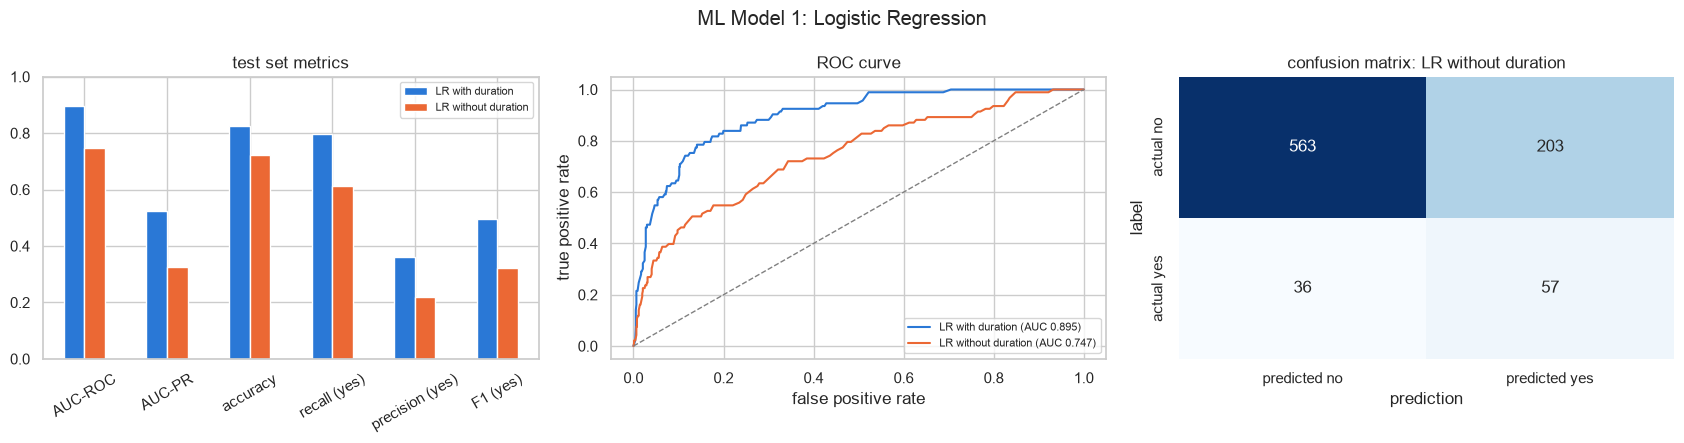

confusion matrix, LR with duration:


prediction,predicted no,predicted yes
label,,
actual no,635,131
actual yes,19,74


In [54]:
# Visualizing evaluation Metric Score chart
report(results, preds, "LR without duration", "ML Model 1: Logistic Regression")
print("confusion matrix, LR with duration:")
confusion(preds["LR with duration"])

**Logistic regression** models the log odds of a 'yes' as a weighted sum of the features, so each coefficient shows how much a feature pushes the chance up or down. It is simple, fast and easy to explain, which makes it a good first model.

**How Spark trains it in a distributed way:** the training data sits in 8 partitions. In every iteration of the optimizer (L-BFGS, or OWL-QN when there is an L1 penalty), each partition computes the loss and gradient for its own rows in parallel. Spark then combines these partial gradients with treeAggregate and the driver updates the weights. On a cluster the partitions would sit on different machines, and the code would not change at all.

**Performance on the test set (859 clients, 93 subscribers):**
- **With duration:** AUC-ROC 0.895, AUC-PR 0.526, and it finds 74 of the 93 subscribers (recall 0.80).
- **Without duration:** AUC-ROC 0.747 and AUC-PR 0.327. It still finds 57 of the 93 subscribers (recall 0.61), but with 203 false alarms, so the precision for 'yes' is 0.22.

The gap shows how much duration helps. But that information is only there after the call. Accuracy (0.72 without duration) looks lower than always saying no, but that is expected with class weights: the model trades a few correct "no" answers for finding many more real subscribers.

#### 2. Cross- Validation & Hyperparameter Tuning

,regParam,elasticNetParam,cv_auc_pr
3,0.01,0.5,0.3539
0,0.00,0.0,0.3534
1,0.00,0.5,0.3534
2,0.01,0.0,0.3529
4,0.10,0.0,0.3477
5,0.10,0.5,0.3121


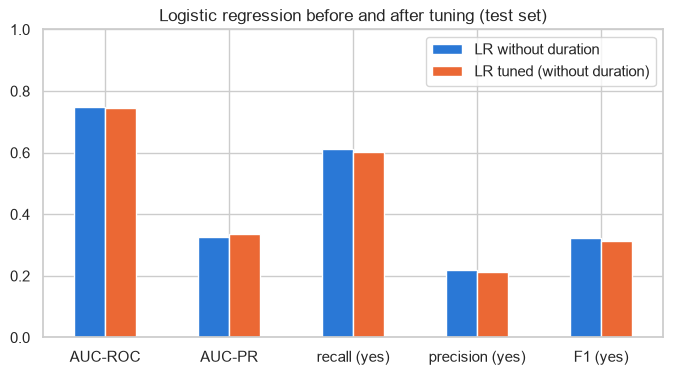

,LR without duration,LR tuned (without duration)
AUC-ROC,0.7473,0.7439
AUC-PR,0.3268,0.3368
accuracy,0.7218,0.7159
weighted precision,0.8619,0.8594
weighted recall,0.7218,0.7159
weighted F1,0.7706,0.7660
precision (yes),0.2192,0.2129
recall (yes),0.6129,0.6022
F1 (yes),0.3229,0.3146


In [55]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# grid search with 3-fold cross validation on the training set, scored on area under the PR curve.
# parallelism=4 trains 4 models of the grid at the same time
lr_cv = LogisticRegression(featuresCol="scaled_features", labelCol="label", weightCol="class_weight", maxIter=100)
grid = (ParamGridBuilder()
        .addGrid(lr_cv.regParam, [0.0, 0.01, 0.1])
        .addGrid(lr_cv.elasticNetParam, [0.0, 0.5])
        .build())
cv = CrossValidator(estimator=build_pipeline(lr_cv, with_duration=False, scale=True), estimatorParamMaps=grid,
                    evaluator=pr_eval, numFolds=3, parallelism=4, seed=42)
# Fit the Algorithm
lr_cv_model = cv.fit(train_w)
grid_table = pd.DataFrame([{p.name: v for p, v in pm.items()} for pm in grid]).assign(cv_auc_pr=np.round(lr_cv_model.avgMetrics, 4))
display(grid_table.sort_values("cv_auc_pr", ascending=False))
# Predict on the model
preds["LR tuned (without duration)"] = lr_cv_model.bestModel.transform(test)
all_results["LR tuned (without duration)"] = evaluate(preds["LR tuned (without duration)"], "LR tuned (without duration)")
compare = pd.DataFrame({k: all_results[k] for k in ["LR without duration", "LR tuned (without duration)"]})
compare.T[["AUC-ROC", "AUC-PR", "recall (yes)", "precision (yes)", "F1 (yes)"]].T.plot(kind="bar", figsize=(8, 4), rot=0,
                                                                                    color=[NO_COLOR, YES_COLOR], ylim=(0, 1))
plt.title("Logistic regression before and after tuning (test set)")
plt.show()
compare

##### Which hyperparameter optimization technique have you used and why?

I used a **grid search with 3 fold cross validation** (ParamGridBuilder + CrossValidator) over regParam (0, 0.01, 0.1) and elasticNetParam (0 = ridge, 0.5 = half lasso). The score was the area under the precision-recall curve, which is the best summary for an imbalanced target. The grid is small (6 combinations, 18 fits), so a full grid search is cheap, and CrossValidator's parallelism=4 trains 4 models at the same time. On bigger data I would switch to a random subset of the grid.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

A small one. The best setting was regParam 0.01 with elasticNetParam 0.5 (cross validation AUC-PR 0.354). On the test set AUC-PR went from 0.327 to 0.337, while AUC-ROC moved from 0.747 to 0.744 and recall for 'yes' from 0.613 to 0.602, so the ranking of clients got a bit better at the top but the overall picture is the same. Logistic regression has few knobs, so tuning was never going to change much.

### ML Model - 2

In [56]:
# ML Model - 2 Implementation
# Random forest with class weights, with and without duration
rf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="class_weight",
                            numTrees=100, maxDepth=6, seed=42)
results, preds_rf = {}, {}
for with_duration in [True, False]:
    name = f"RF {'with' if with_duration else 'without'} duration"
    # Fit the Algorithm
    fitted[name] = build_pipeline(rf, with_duration).fit(train_w)
    # Predict on the model
    preds_rf[name] = fitted[name].transform(test)
    results[name] = evaluate(preds_rf[name], name)
preds.update(preds_rf)
all_results.update(results)
pd.DataFrame(results)

,RF with duration,RF without duration
AUC-ROC,0.8870,0.7441
AUC-PR,0.4934,0.3261
accuracy,0.8114,0.7567
weighted precision,0.8964,0.8601
weighted recall,0.8114,0.7567
weighted F1,0.8399,0.7951
precision (yes),0.3349,0.2364
recall (yes),0.7527,0.5591
F1 (yes),0.4636,0.3323


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

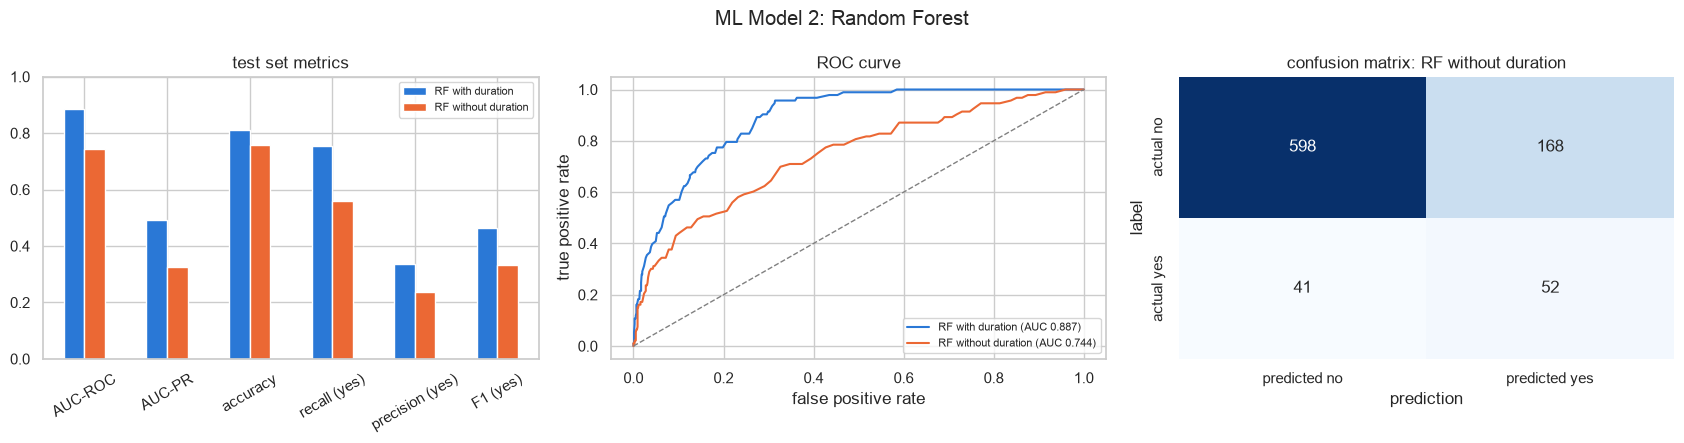

In [57]:
# Visualizing evaluation Metric Score chart
report(results, preds_rf, "RF without duration", "ML Model 2: Random Forest")

**Random forest** trains many decision trees (100 here, each up to depth 6), each on a random sample of the rows and with a random subset of features at every split, and the trees vote. It can pick up non linear patterns, like the high subscription rate of both the youngest and the oldest clients.

**How Spark trains it in a distributed way:** Spark grows the trees level by level. For the nodes at the current level, every partition computes split statistics for its rows (counts per bin, with each feature cut into at most 32 bins). These statistics are aggregated across partitions, and the driver picks the best split for each node. Many trees are grown at the same time, so the work is spread over all the cores.

**Performance on the test set:**
- **With duration:** AUC-ROC 0.887 and AUC-PR 0.493.
- **Without duration:** AUC-ROC 0.744 and AUC-PR 0.326, almost the same as logistic regression. It flags fewer clients than logistic regression: 52 of the 93 subscribers found (recall 0.56), with a slightly better precision of 0.24.

#### 2. Cross- Validation & Hyperparameter Tuning

,numTrees,maxDepth,cv_auc_pr
0,100,6,0.3357
2,200,6,0.3315
3,200,10,0.3104
1,100,10,0.3069


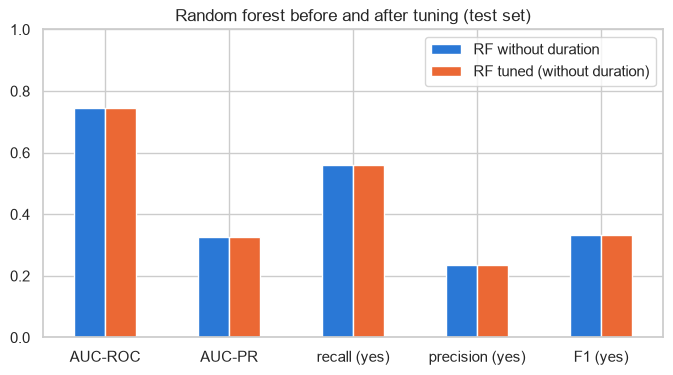

,RF without duration,RF tuned (without duration)
AUC-ROC,0.7441,0.7441
AUC-PR,0.3261,0.3261
accuracy,0.7567,0.7567
weighted precision,0.8601,0.8601
weighted recall,0.7567,0.7567
weighted F1,0.7951,0.7951
precision (yes),0.2364,0.2364
recall (yes),0.5591,0.5591
F1 (yes),0.3323,0.3323


In [58]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
rf_cv = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="class_weight", seed=42)
grid = (ParamGridBuilder()
        .addGrid(rf_cv.numTrees, [100, 200])
        .addGrid(rf_cv.maxDepth, [6, 10])
        .build())
cv = CrossValidator(estimator=build_pipeline(rf_cv, with_duration=False), estimatorParamMaps=grid,
                    evaluator=pr_eval, numFolds=3, parallelism=4, seed=42)
# Fit the Algorithm
rf_cv_model = cv.fit(train_w)
grid_table = pd.DataFrame([{p.name: v for p, v in pm.items()} for pm in grid]).assign(cv_auc_pr=np.round(rf_cv_model.avgMetrics, 4))
display(grid_table.sort_values("cv_auc_pr", ascending=False))
# Predict on the model
preds["RF tuned (without duration)"] = rf_cv_model.bestModel.transform(test)
all_results["RF tuned (without duration)"] = evaluate(preds["RF tuned (without duration)"], "RF tuned (without duration)")
compare = pd.DataFrame({k: all_results[k] for k in ["RF without duration", "RF tuned (without duration)"]})
compare.T[["AUC-ROC", "AUC-PR", "recall (yes)", "precision (yes)", "F1 (yes)"]].T.plot(kind="bar", figsize=(8, 4), rot=0,
                                                                                    color=[NO_COLOR, YES_COLOR], ylim=(0, 1))
plt.title("Random forest before and after tuning (test set)")
plt.show()
compare

##### Which hyperparameter optimization technique have you used and why?

Again a grid search with 3 fold cross validation on AUC-PR, this time over numTrees (100, 200) and maxDepth (6, 10). These two parameters matter most for a forest: more trees make it more stable, deeper trees can learn more detail but also overfit.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

No. The best combination was the one I already used, 100 trees with depth 6 (cross validation AUC-PR 0.336), so the test results did not change. Deeper trees were clearly worse (0.307 to 0.310). That is useful to know in itself: with this little signal and 428 'yes' rows, deep trees start learning noise.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

- **AUC-ROC**: how well the model ranks a random subscriber above a random non subscriber. 0.5 is guessing, 1.0 is perfect. It tells the bank if the model's ranking of clients can be trusted.
- **AUC-PR**: the same idea, focused only on the 'yes' class, so it is the most honest metric with so few subscribers. Random guessing scores the share of subscribers (0.108 on the test set).
- **Recall (yes)**: the share of real subscribers the model finds. Every subscriber the model misses is a lost deposit.
- **Precision (yes)**: the share of flagged clients who really subscribe. Low precision means wasted calls.
- **F1 (yes)**: balances recall and precision in one number.
- **Accuracy and the weighted metrics**: mostly measure how well the model says "no", which is easy here, so they matter least.

For the business, recall and precision for 'yes' are the trade-off: calling more flagged clients finds more subscribers but costs more calls. A call is cheap compared to the value of a deposit, so I care more about recall than precision, while AUC-PR tells me how good the overall ranking is.

### ML Model - 3

In [59]:
# ML Model - 3 Implementation
# Gradient boosted trees (GBTClassifier) with class weights, with and without duration
gbt = GBTClassifier(featuresCol="features", labelCol="label", weightCol="class_weight",
                    maxIter=30, maxDepth=4, stepSize=0.1, seed=42)
results, preds_gbt = {}, {}
for with_duration in [True, False]:
    name = f"GBT {'with' if with_duration else 'without'} duration"
    # Fit the Algorithm
    fitted[name] = build_pipeline(gbt, with_duration).fit(train_w)
    # Predict on the model
    preds_gbt[name] = fitted[name].transform(test)
    results[name] = evaluate(preds_gbt[name], name)
preds.update(preds_gbt)
all_results.update(results)
pd.DataFrame(results)

,GBT with duration,GBT without duration
AUC-ROC,0.8863,0.7131
AUC-PR,0.4668,0.2939
accuracy,0.8219,0.7066
weighted precision,0.9086,0.8580
weighted recall,0.8219,0.7066
weighted F1,0.8493,0.7591
precision (yes),0.3598,0.2066
recall (yes),0.8280,0.6022
F1 (yes),0.5016,0.3077


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

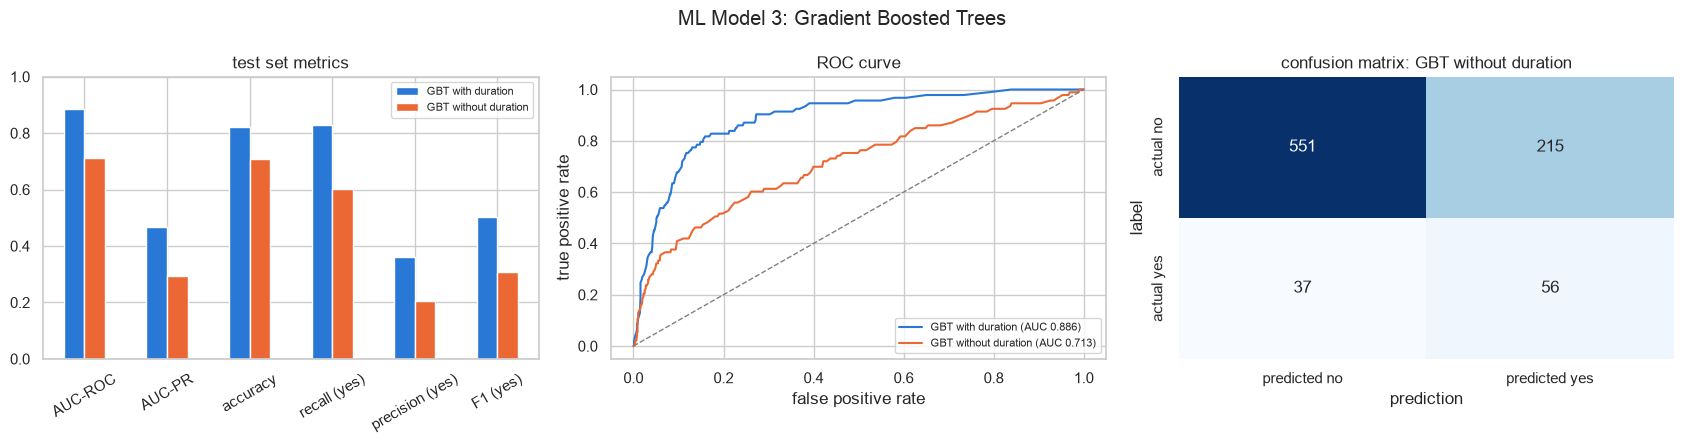

In [60]:
# Visualizing evaluation Metric Score chart
report(results, preds_gbt, "GBT without duration", "ML Model 3: Gradient Boosted Trees")

**Gradient boosted trees** build small trees one after the other, and every new tree tries to fix the mistakes of the trees before it. Boosting often gives the best results on tabular data.

**How Spark trains it in a distributed way:** the trees are built one after the other, because each one needs the errors of the previous ones. But each tree is built the same distributed way as in the random forest, with split statistics computed on every partition and aggregated. So the parallel part is inside each tree.

**Performance on the test set (base settings: 30 trees of depth 4):**
- **With duration:** AUC-ROC 0.886 and AUC-PR 0.467, with the highest recall of all models (0.83, 77 of 93 subscribers).
- **Without duration:** it is the weakest of the three before tuning: AUC-ROC 0.713 and AUC-PR 0.294. It finds 56 of the 93 subscribers (recall 0.60) with 215 false alarms.

#### 2. Cross- Validation & Hyperparameter Tuning

,maxDepth,maxIter,cv_auc_pr
0,3,30,0.3285
1,3,60,0.3163
2,5,30,0.2727
3,5,60,0.2554


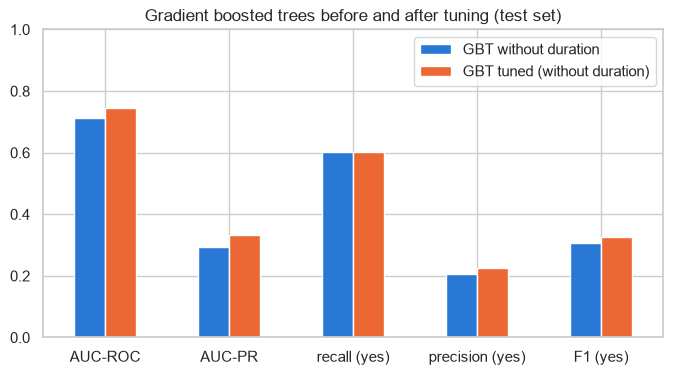

,GBT without duration,GBT tuned (without duration)
AUC-ROC,0.7131,0.7436
AUC-PR,0.2939,0.3327
accuracy,0.7066,0.7311
weighted precision,0.8580,0.8618
weighted recall,0.7066,0.7311
weighted F1,0.7591,0.7773
precision (yes),0.2066,0.2240
recall (yes),0.6022,0.6022
F1 (yes),0.3077,0.3265


In [61]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
gbt_cv = GBTClassifier(featuresCol="features", labelCol="label", weightCol="class_weight", stepSize=0.1, seed=42)
grid = (ParamGridBuilder()
        .addGrid(gbt_cv.maxDepth, [3, 5])
        .addGrid(gbt_cv.maxIter, [30, 60])
        .build())
cv = CrossValidator(estimator=build_pipeline(gbt_cv, with_duration=False), estimatorParamMaps=grid,
                    evaluator=pr_eval, numFolds=3, parallelism=4, seed=42)
# Fit the Algorithm
gbt_cv_model = cv.fit(train_w)
grid_table = pd.DataFrame([{p.name: v for p, v in pm.items()} for pm in grid]).assign(cv_auc_pr=np.round(gbt_cv_model.avgMetrics, 4))
display(grid_table.sort_values("cv_auc_pr", ascending=False))
# Predict on the model
preds["GBT tuned (without duration)"] = gbt_cv_model.bestModel.transform(test)
all_results["GBT tuned (without duration)"] = evaluate(preds["GBT tuned (without duration)"], "GBT tuned (without duration)")
compare = pd.DataFrame({k: all_results[k] for k in ["GBT without duration", "GBT tuned (without duration)"]})
compare.T[["AUC-ROC", "AUC-PR", "recall (yes)", "precision (yes)", "F1 (yes)"]].T.plot(kind="bar", figsize=(8, 4), rot=0,
                                                                                    color=[NO_COLOR, YES_COLOR], ylim=(0, 1))
plt.title("Gradient boosted trees before and after tuning (test set)")
plt.show()
compare

##### Which hyperparameter optimization technique have you used and why?

A grid search with 3 fold cross validation on AUC-PR over maxDepth (3, 5) and maxIter (30, 60 trees), with the step size fixed at 0.1. Depth and the number of boosting rounds control how complex a boosted model gets, so they are the first parameters to tune.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, the biggest improvement of the three models. The best setting was the simplest one, depth 3 with 30 trees (cross validation AUC-PR 0.329). Deeper trees did clearly worse (0.255 to 0.273). On the test set, AUC-PR went from 0.294 to 0.333, AUC-ROC from 0.713 to 0.744 and F1 for 'yes' from 0.308 to 0.327, with the same recall (0.60) and fewer false alarms (194 instead of 215). So the default boosting was overfitting, and smaller trees generalize better.

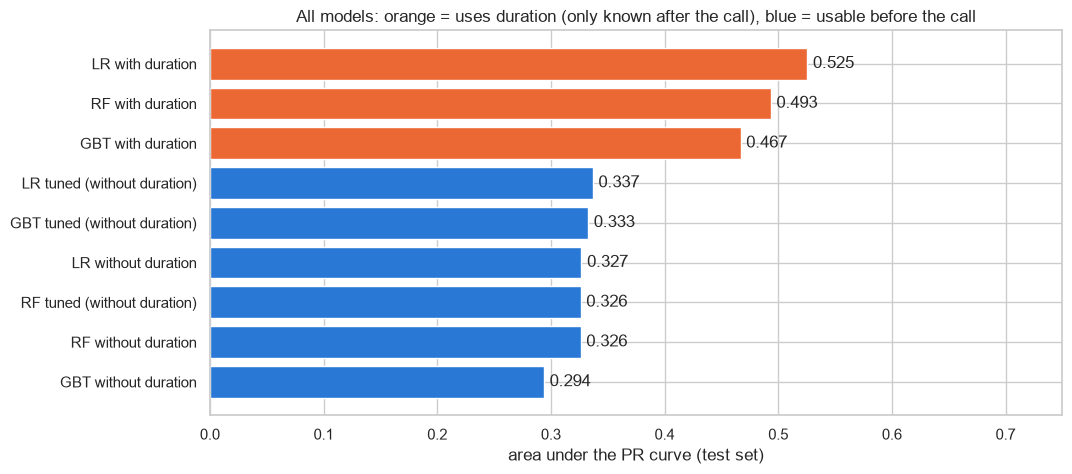

best cross validation AUC-PR: {'LR tuned (without duration)': np.float64(0.3539), 'RF tuned (without duration)': np.float64(0.3357), 'GBT tuned (without duration)': np.float64(0.3285)}
final model: LR tuned (without duration)


,AUC-ROC,AUC-PR,accuracy,weighted F1,precision (yes),recall (yes),F1 (yes)
LR with duration,0.8950,0.5255,0.8254,0.8513,0.3610,0.7957,0.4966
LR without duration,0.7473,0.3268,0.7218,0.7706,0.2192,0.6129,0.3229
LR tuned (without duration),0.7439,0.3368,0.7159,0.7660,0.2129,0.6022,0.3146
RF with duration,0.8870,0.4934,0.8114,0.8399,0.3349,0.7527,0.4636
RF without duration,0.7441,0.3261,0.7567,0.7951,0.2364,0.5591,0.3323
RF tuned (without duration),0.7441,0.3261,0.7567,0.7951,0.2364,0.5591,0.3323
GBT with duration,0.8863,0.4668,0.8219,0.8493,0.3598,0.8280,0.5016
GBT without duration,0.7131,0.2939,0.7066,0.7591,0.2066,0.6022,0.3077
GBT tuned (without duration),0.7436,0.3327,0.7311,0.7773,0.2240,0.6022,0.3265


In [62]:
# all models side by side on the same test set
summary = pd.DataFrame(all_results).T[["AUC-ROC", "AUC-PR", "accuracy", "weighted F1", "precision (yes)", "recall (yes)", "F1 (yes)"]]
fig, ax = plt.subplots(figsize=(11, 5))
plot = summary.sort_values("AUC-PR")
ax.barh(plot.index, plot["AUC-PR"], color=[YES_COLOR if "with duration" in i else NO_COLOR for i in plot.index])
for i, v in enumerate(plot["AUC-PR"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.set_xlabel("area under the PR curve (test set)")
ax.set_title("All models: orange = uses duration (only known after the call), blue = usable before the call")
ax.set_xlim(0, 0.75)
plt.show()

# the final model is the tuned model without duration with the best cross validation AUC-PR
# (chosen on the training folds, the test set only confirms it)
tuned = {"LR tuned (without duration)": lr_cv_model, "RF tuned (without duration)": rf_cv_model,
         "GBT tuned (without duration)": gbt_cv_model}
print("best cross validation AUC-PR:", {k: round(max(m.avgMetrics), 4) for k, m in tuned.items()})
final_name = max(tuned, key=lambda k: max(tuned[k].avgMetrics))
final_model = tuned[final_name].bestModel
print("final model:", final_name)
summary.round(4)

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

I used **AUC-PR** as my main metric, both to tune the models and to choose the final one. With only 11% subscribers it shows how good the model is at the part the bank cares about: putting the real subscribers at the top of the list. AUC-ROC can look good even when the top of the list is poor.

Next to that I looked at **recall and precision for 'yes'**. Recall is how many future deposits the bank reaches, and precision is how many calls are wasted. A missed subscriber costs more than one extra call, so recall matters a bit more. I did not use accuracy to choose, because always saying no would already score 88.5%.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

I chose the **tuned logistic regression without duration** (regParam 0.01, elasticNetParam 0.5).

- **Why without duration:** the model has to decide who to call before the call happens, and duration is only known afterwards. The models with duration score much higher (AUC-ROC around 0.89), but in practice those numbers are not reachable. The original dataset description also says duration should be dropped for a realistic model.
- **Why logistic regression:** it had the best cross validation AUC-PR of the three tuned models (0.354, against 0.336 for the random forest and 0.329 for boosting), and the test set agrees (AUC-PR 0.337 against 0.326 and 0.333). The three are close, so the simpler model wins: it is fast, its coefficients are easy to explain to the marketing team, and it predicts quickly in the streaming part of the project.

**What it means in practice:** on the test set the model flags 263 of 859 clients (31%) and among them are 56 of the 93 real subscribers (60%). One in five flagged clients subscribes (precision 0.21), twice the 1 in 10 of calling everybody. So the bank could make 69% fewer calls and still reach 60% of the people who would subscribe.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

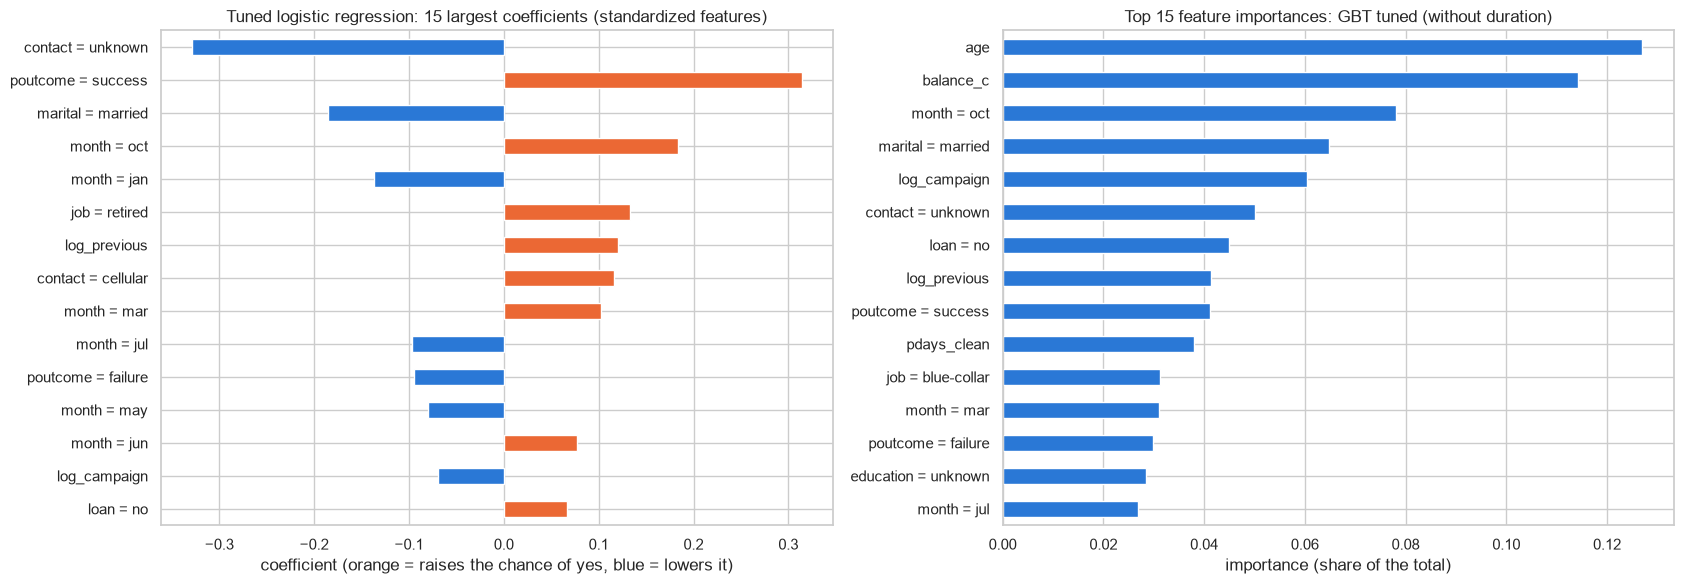

final model: LR tuned (without duration) {'elasticNetParam': 0.5, 'maxIter': 100, 'regParam': 0.01}
best tree model: GBT tuned (without duration) {'maxDepth': 3, 'maxIter': 30, 'stepSize': 0.1}
odds ratio of the 5 largest logistic regression coefficients (per standard deviation of the feature):


contact = unknown     0.72
poutcome = success    1.37
marital = married     0.83
month = oct           1.20
month = jan           0.87
dtype: float64

age                   0.1269
balance_c             0.1142
month = oct           0.0782
marital = married     0.0647
log_campaign          0.0604
contact = unknown     0.0502
loan = no             0.0449
log_previous          0.0415
poutcome = success    0.0412
pdays_clean           0.0380
dtype: float64

In [63]:
# what drives the predictions: coefficients of the tuned logistic regression and
# feature importances of the best tree model (trees give importances, logistic regression gives coefficients)
final_pred = final_model.transform(test)

lr_best = lr_cv_model.bestModel
lr_pred = lr_best.transform(test)
lr_coef = pd.Series(lr_best.stages[-1].coefficients.toArray(), index=feature_names(lr_pred))
lr_top = lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).index[:15])

tree_name = max(["RF tuned (without duration)", "GBT tuned (without duration)"], key=lambda k: all_results[k]["AUC-PR"])
tree_best = tuned[tree_name].bestModel
tree_pred = tree_best.transform(test)
importance = pd.Series(tree_best.stages[-1].featureImportances.toArray(), index=feature_names(tree_pred)).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
lr_top[::-1].plot(kind="barh", ax=axes[0], color=[YES_COLOR if v > 0 else NO_COLOR for v in lr_top[::-1]])
axes[0].set_title("Tuned logistic regression: 15 largest coefficients (standardized features)")
axes[0].set_xlabel("coefficient (orange = raises the chance of yes, blue = lowers it)")
importance.head(15)[::-1].plot(kind="barh", ax=axes[1], color=NO_COLOR)
axes[1].set_title(f"Top 15 feature importances: {tree_name}")
axes[1].set_xlabel("importance (share of the total)")
plt.tight_layout()
plt.show()

def best_params(model):
    return {p.name: v for p, v in model.stages[-1].extractParamMap().items()
            if p.name in ("maxDepth", "maxIter", "numTrees", "stepSize", "regParam", "elasticNetParam")}

print("final model:", final_name, best_params(final_model))
print("best tree model:", tree_name, best_params(tree_best))
print("odds ratio of the 5 largest logistic regression coefficients (per standard deviation of the feature):")
display(np.exp(lr_top.head(5)).round(2))
importance.head(10).round(4)

The final model is a logistic regression, so its **coefficients** explain it directly. The features are standardized, so a coefficient is the change in log odds for one standard deviation of the feature, and exp(coefficient) is the odds ratio.

**What the logistic regression coefficients say:**
- **contact = unknown** lowers the odds the most (odds ratio 0.72).
- **poutcome = success** raises them the most (1.37). A client who said yes last time is the best lead.
- **marital = married** lowers the odds (0.83), and so does a call in **January** (0.87).
- A call in **October** raises them (1.20).

These match the charts: the previous success rate of 64%, the low 4.6% for unknown contacts, and the strong months.

To check this from another angle I also looked at the **feature importances of the best tree model**, the tuned gradient boosted trees. Its top features are:
- **age** (0.127) and **balance** (0.114): the trees use them to find the high rates of older clients and students, which a straight line can't capture.
- then **month = oct** (0.078), **marital = married** (0.065), the number of calls (0.060) and **contact = unknown** (0.050).

So both models agree on the main story: who the client is (age, family status, money), when and how they are called (month, channel, number of calls), and whether they bought before.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [64]:
# Save the File
# a Spark ML PipelineModel is saved as a folder (every stage with its learned values), not as a pickle file
MODEL_DIR = "model"
final_model.write().overwrite().save(MODEL_DIR)
print("saved to", os.path.abspath(MODEL_DIR))
print(sorted(os.listdir(os.path.join(MODEL_DIR, "stages"))))

saved to /Users/taha/Desktop/Distributed ML/bank-distributed-ml/part3_spark_ml/model
['0_SQLTransformer_021524056768', '1_StringIndexer_6dcfc2d78089', '2_OneHotEncoder_8c857089ba3e', '3_VectorAssembler_e71adfcd47a1', '4_StandardScaler_89232d5bcb68', '5_LogisticRegression_d1ed3d56dceb']


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [65]:
# Load the File and predict unseen data.
loaded = PipelineModel.load(MODEL_DIR)

# 1) a few rows of the test set, which the model never saw during training
sample = test.drop("label", "row_id").limit(6)
(loaded.transform(sample)
       .select("age", "job", "balance", "poutcome", "month", "y",
               F.round(vector_to_array("probability")[1], 3).alias("prob_yes"), "prediction")
       .show())

# 2) three made up clients, only the raw columns of bank.csv are needed (y is not)
new_clients = spark.createDataFrame([
    (35, "management", "married", "tertiary", "no", 2500, "no", "no", "cellular", 15, "oct", 0, 1, 90, 2, "success"),
    (45, "blue-collar", "married", "secondary", "no", 150, "yes", "yes", "unknown", 20, "may", 0, 4, -1, 0, "unknown"),
    (68, "retired", "divorced", "primary", "no", 9000, "no", "no", "telephone", 3, "mar", 0, 1, -1, 0, "unknown")],
    ["age", "job", "marital", "education", "default", "balance", "housing", "loan", "contact", "day", "month",
     "duration", "campaign", "pdays", "previous", "poutcome"])
(loaded.transform(new_clients)
       .select("age", "job", "balance", "contact", "month", "poutcome",
               F.round(vector_to_array("probability")[1], 3).alias("prob_yes"), "prediction")
       .show())
same = loaded.transform(test).select("prediction").collect() == final_pred.select("prediction").collect()
print("loaded model gives the same predictions as the trained one:", same)

+---+-------------+-------+--------+-----+---+--------+----------+
|age|          job|balance|poutcome|month|  y|prob_yes|prediction|
+---+-------------+-------+--------+-----+---+--------+----------+
| 35|   management|   1350| failure|  apr| no|   0.594|       1.0|
| 36|self-employed|    307|   other|  may| no|   0.596|       1.0|
| 41| entrepreneur|    221| unknown|  may| no|   0.235|       0.0|
| 20|      student|    502| unknown|  apr|yes|   0.665|       1.0|
| 31|     services|    132|   other|  jul| no|   0.542|       1.0|
| 44| entrepreneur|     93| unknown|  jul| no|   0.416|       0.0|
+---+-------------+-------+--------+-----+---+--------+----------+

+---+-----------+-------+---------+-----+--------+--------+----------+
|age|        job|balance|  contact|month|poutcome|prob_yes|prediction|
+---+-----------+-------+---------+-----+--------+--------+----------+
| 35| management|   2500| cellular|  oct| success|   0.975|       1.0|
| 45|blue-collar|    150|  unknown|  may| unk

loaded model gives the same predictions as the trained one: True


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

- With Spark ML I built a full classification pipeline on the bank marketing data, from feature engineering through StringIndexer, OneHotEncoder and VectorAssembler to the model, all in one Pipeline that is saved and reloaded as a whole. Because it is Spark, the same code works on a cluster: the data is split into partitions, gradients and split statistics are aggregated across them, and CrossValidator trains several models in parallel.
- The data had no nulls, but the placeholder values ('unknown', pdays = -1) needed real decisions. Keeping them as information was better than replacing them.
- The strongest signals are the outcome of the previous campaign (64.3% subscribe after a success), the month (May is busy but converts only 6.7%), the contact channel, loans, and calling the same client again and again, which mostly wastes calls.
- duration looks like the best feature, but it is only known after the call. With it the models reach an AUC-ROC of about 0.89, without it about 0.74. I chose the realistic version.
- The final model is a tuned logistic regression with class weights: AUC-ROC 0.744, AUC-PR 0.337 (three times random). By calling only the 31% of clients it flags, the bank would still reach 60% of the subscribers, and twice as many calls would end in a deposit.
- Next steps: add more history per client and test the model in a real campaign. More data would also give the tree models more room to beat the simple linear model.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***